# Librerías 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score,roc_curve,auc,confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.metrics import recall_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.feature_selection import SequentialFeatureSelector

--------------------------------------
# Carga dataset para exploración 

In [3]:
churn = pd.read_excel("DATA.xlsx")
churn

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN


In [4]:
print(churn.shape)

(7043, 33)


--------------------------------------------
# Análisis de tipos de dato

In [5]:
churn.dtypes

CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges         object
Churn Label           object
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason          object
dtype: object


La columna total Charges debería ser de tipo float, el problema es que si cambiamos el tipo da el siguiente error:


ValueError: could not convert string to float: ' '

Eso significa que hay espacios que imposibilitan el cambio de tipo al float, por ello reemplazaremos los espacios por na y luego los analizaremos


In [6]:
espacios_en_blanco = churn[churn['Total Charges'] == ' ']
espacios_en_blanco

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
2234,4472-LVYGI,1,United States,California,San Bernardino,92408,"34.084909, -117.258107",34.084909,-117.258107,Female,...,Two year,Yes,Bank transfer (automatic),52.55,,No,0,36,2578,NaN
2438,3115-CZMZD,1,United States,California,Independence,93526,"36.869584, -118.189241",36.869584,-118.189241,Male,...,Two year,No,Mailed check,20.25,,No,0,68,5504,NaN
2568,5709-LVOEQ,1,United States,California,San Mateo,94401,"37.590421, -122.306467",37.590421,-122.306467,Female,...,Two year,No,Mailed check,80.85,,No,0,45,2048,NaN
2667,4367-NUYAO,1,United States,California,Cupertino,95014,"37.306612, -122.080621",37.306612,-122.080621,Male,...,Two year,No,Mailed check,25.75,,No,0,48,4950,NaN
2856,1371-DWPAZ,1,United States,California,Redcrest,95569,"40.363446, -123.835041",40.363446,-123.835041,Female,...,Two year,No,Credit card (automatic),56.05,,No,0,30,4740,NaN
4331,7644-OMVMY,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,...,Two year,No,Mailed check,19.85,,No,0,53,2019,NaN
4687,3213-VVOLG,1,United States,California,Sun City,92585,"33.739412, -117.173334",33.739412,-117.173334,Male,...,Two year,No,Mailed check,25.35,,No,0,49,2299,NaN
5104,2520-SGTTA,1,United States,California,Ben Lomond,95005,"37.078873, -122.090386",37.078873,-122.090386,Female,...,Two year,No,Mailed check,20.00,,No,0,27,3763,NaN
5719,2923-ARZLG,1,United States,California,La Verne,91750,"34.144703, -117.770299",34.144703,-117.770299,Male,...,One year,Yes,Mailed check,19.70,,No,0,69,4890,NaN
6772,4075-WKNIU,1,United States,California,Bell,90201,"33.970343, -118.171368",33.970343,-118.171368,Female,...,Two year,No,Mailed check,73.35,,No,0,44,2342,NaN


In [7]:
churn['Total Charges'] = churn['Total Charges'].replace(' ', np.nan)

# Convierte la columna a float. Ahora ya no dará error.
churn['Total Charges'] = churn['Total Charges'].astype(float)

C:\Users\koki2\AppData\Local\Temp\ipykernel_18420\3810830123.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  churn['Total Charges'] = churn['Total Charges'].replace(' ', np.nan)


------------------
# Análisis de nulls

In [8]:
churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [9]:
print(churn['Churn Value'].value_counts())

Churn Value
0    5174
1    1869
Name: count, dtype: int64


Si nos fijamos bien se ve que todas las columnas tienen todos los valores no nulos excepto 'Churn Reason' (la última). Esto tiene sentido porque como podemos comprobar 1869 es el número de valores no nulos y se corresponde con el número de filas que tienen valor 1 (abandono), así que tiene sentido. Vamos a sustituir los nulos entonces por el valor 'se_queda'.  

In [10]:
churn['Churn Reason'] = churn['Churn Reason'].fillna('se_queda')

In [11]:
churn['Churn Reason'].isna().sum()
print(churn["Churn Reason"].value_counts())

Churn Reason
se_queda                                     5174
Attitude of support person                    192
Competitor offered higher download speeds     189
Competitor offered more data                  162
Don't know                                    154
Competitor made better offer                  140
Attitude of service provider                  135
Competitor had better devices                 130
Network reliability                           103
Product dissatisfaction                       102
Price too high                                 98
Service dissatisfaction                        89
Lack of self-service on Website                88
Extra data charges                             57
Moved                                          53
Limited range of services                      44
Lack of affordable download/upload speed       44
Long distance charges                          44
Poor expertise of phone support                20
Poor expertise of online support     

Para atribuir los nulls a la columna de Total Charges primero vamos a ver como se distribuyen sus datos

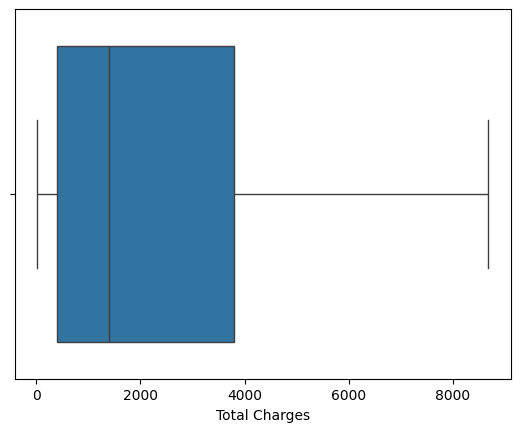

In [12]:
sns.boxplot(data = churn, x=churn['Total Charges'])
plt.show()

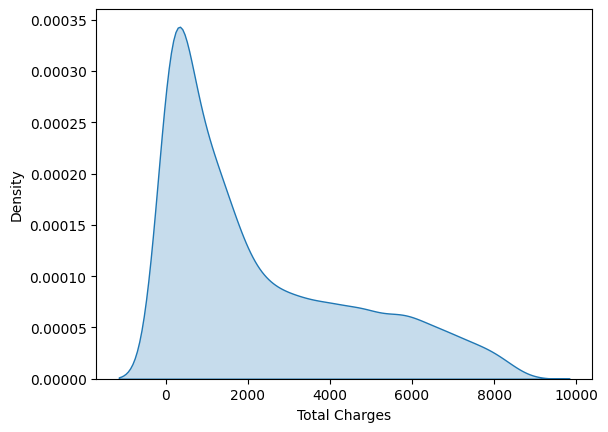

In [13]:
sns.kdeplot(data = churn, x = 'Total Charges', fill = True)
plt.show()

In [14]:
print(churn['Total Charges'].describe())

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: Total Charges, dtype: float64


Como se puede ver gracias al .describe() y al kdeplot, la media se ve afectada por unos valores altos que estan sesgando la distribución entonces es mejor aplicar la mediana.

In [15]:
mediana_cargos = churn['Total Charges'].median()

In [16]:
churn['Total Charges'].fillna(mediana_cargos, inplace=True)

C:\Users\koki2\AppData\Local\Temp\ipykernel_18420\4195289185.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  churn['Total Charges'].fillna(mediana_cargos, inplace=True)


---------------------------------------------

# Comprobación de valores duplicados

In [17]:
churn[churn['CustomerID'].duplicated()]

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason


Hemos comprobado que no hay duplicados en la única columna que tiene sentido que no haya dulpicados, CustomerID

------------------------------------------------------------------------

# Eliminación de columnas innecesarias

In [18]:
print('Países diferentes:')
print(churn['Country'].unique())
print('Estados diferentes:')
print(churn['State'].unique())
print('Ciudades diferentes:')
print(churn['City'].nunique())

Países diferentes:
['United States']
Estados diferentes:
['California']
Ciudades diferentes:
1129


Podemos usar las columnas geográficas para analizar si hay diferencias entre regiones, sin embargo realmente solo es útil la de "City", porque la columna de 'State' tiene únicamente el valor "California", la de 'Country' solo tiene el valor "Estados Unidos". La de 'Count' tampoco es muy útil porque suponiendo que el dataset tiene sentido y cada cliente es único el valor va a ser 1 nos podemos quedar directamente con CustomerID.

In [19]:
churn = churn.drop(columns = ['Count','State','Country','Zip Code', 'Lat Long','Latitude','Longitude'])

------------
# Comprobación outliers y valores sin sentido

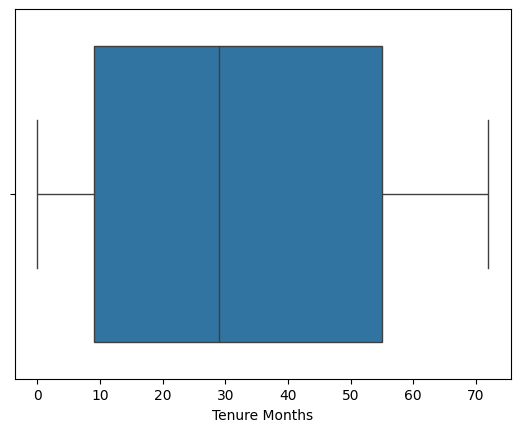

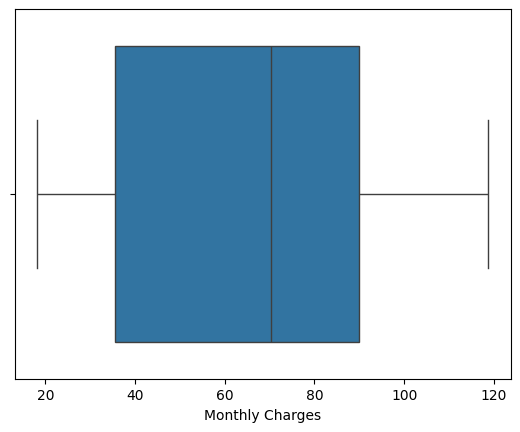

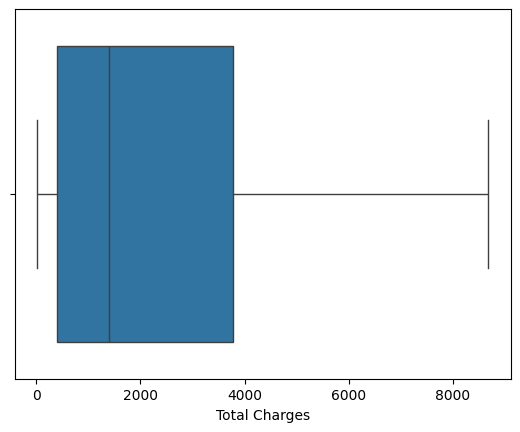

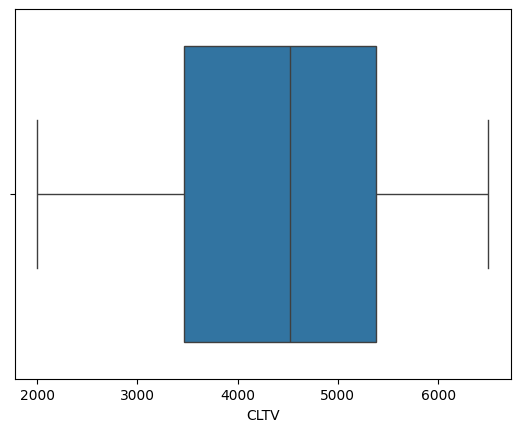

In [20]:
lista_columnas_outliers = ['Tenure Months','Monthly Charges','Total Charges','CLTV']
for n in lista_columnas_outliers:
    sns.boxplot(data = churn, x = churn[n])
    plt.show()

In [21]:
for n in lista_columnas_outliers:
    print(churn[n].describe())
    print('----------------')

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: Tenure Months, dtype: float64
----------------
count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: Monthly Charges, dtype: float64
----------------
count    7043.000000
mean     2281.916928
std      2265.270398
min        18.800000
25%       402.225000
50%      1397.475000
75%      3786.600000
max      8684.800000
Name: Total Charges, dtype: float64
----------------
count    7043.000000
mean     4400.295755
std      1183.057152
min      2003.000000
25%      3469.000000
50%      4527.000000
75%      5380.500000
max      6500.000000
Name: CLTV, dtype: float64
----------------


Aparentemente no tenemos outliers en las columnas numéricas.

In [22]:
# Nos hemos dado cuenta de que según la descripción del dataset hay columnas que únicamente deberían tienen el valor SI/NO, sin embargo al hacer los histogramas por columnas más abajo hemos encontrado 
# valores que no deberían tener como 'No phone service" y "No internet service" (que básicamente significan "NO"), por ello los vamos a reemplazar a continuación por "No" con un bucle. 

churn["Multiple Lines"] =  churn["Multiple Lines"].replace("No phone service", "No")
churn["Multiple Lines"].value_counts()

columnas_a_transformar_a_no = [
    'Streaming Movies','Streaming TV',
    'Tech Support', 'Device Protection'
    ,'Online Backup', 'Online Security']
for columna in columnas_a_transformar_a_no:
    churn[columna] = churn[columna].replace("No internet service", "No")
    print(f"la columna: '{columna}' \ntiene ahora estos tipos: \n '{churn[columna].value_counts()}'\n")

la columna: 'Streaming Movies' 
tiene ahora estos tipos: 
 'Streaming Movies
No     4311
Yes    2732
Name: count, dtype: int64'

la columna: 'Streaming TV' 
tiene ahora estos tipos: 
 'Streaming TV
No     4336
Yes    2707
Name: count, dtype: int64'

la columna: 'Tech Support' 
tiene ahora estos tipos: 
 'Tech Support
No     4999
Yes    2044
Name: count, dtype: int64'

la columna: 'Device Protection' 
tiene ahora estos tipos: 
 'Device Protection
No     4621
Yes    2422
Name: count, dtype: int64'

la columna: 'Online Backup' 
tiene ahora estos tipos: 
 'Online Backup
No     4614
Yes    2429
Name: count, dtype: int64'

la columna: 'Online Security' 
tiene ahora estos tipos: 
 'Online Security
No     5024
Yes    2019
Name: count, dtype: int64'



-------
# Análisis de patrones 

Este apartado del EDA nos parece especialmente importante porque si bien aplicando algoritmos variados de machine learning podemos encontrar soluciones avanzadas, a veces con un simple histograma o un gráfico de barras podemos encontrar patrones de los datos y proponer soluciones simples que podrían tener igual o más impacto en el éxito del negocio (que al fin y al cabo es el objetivo final).

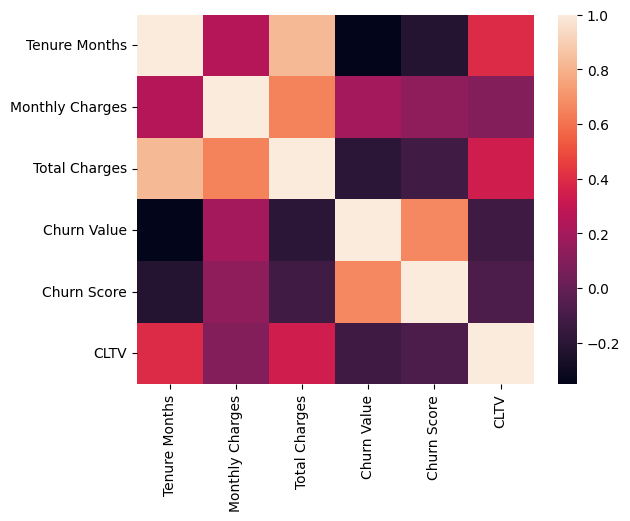

In [23]:
corr = churn.corr(numeric_only=True)
sns.heatmap(data = corr)
plt.show()

Tenure months correlaciona negativamente con el churn value y el churn score, puede significar que a menor cantidad de meses en la compañía los clientes tienen mayor probabilidad de irse y viceversa. Además correlaciona positivamente con el CLTV, lo que es lógico porque cuanto más tiempo con la compañía más dinero gasta y más valor tiene para ella. 

Churn Value
0    0.73463
1    0.26537
Name: proportion, dtype: float64


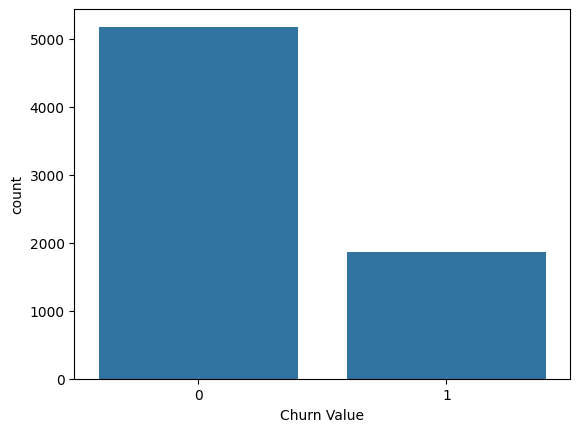

In [24]:
print(churn['Churn Value'].value_counts(normalize=True))

sns.countplot(data = churn, x = churn['Churn Value'])
plt.show()

Contamos con un 26% de clientes que abandonan frente a un 73% que no abandona en el dataset, esto puede tener mayor relevancia luego para los conjuntos de entrenamiento y test. Conviene evaluar el desempeño de los modelos con estratificación. 

In [25]:
filtro_se_van = churn[churn['Churn Value']==1]
lista_razones_abandono = list(filtro_se_van['Churn Reason'].unique())
print(f'Hay en total {len(lista_razones_abandono)} razones diferentes de abandono:\n')
# Se ha hecho el filtro para que no se incluya en el bucle 'se_queda' correspondiente a los que no se han ido

numero = 1
for n in lista_razones_abandono:
    print(f'{numero} - {n}')
    numero = numero +1

Hay en total 20 razones diferentes de abandono:

1 - Competitor made better offer
2 - Moved
3 - Competitor had better devices
4 - Competitor offered higher download speeds
5 - Competitor offered more data
6 - Price too high
7 - Product dissatisfaction
8 - Service dissatisfaction
9 - Lack of self-service on Website
10 - Network reliability
11 - Limited range of services
12 - Lack of affordable download/upload speed
13 - Long distance charges
14 - Extra data charges
15 - Don't know
16 - Poor expertise of online support
17 - Poor expertise of phone support
18 - Attitude of service provider
19 - Attitude of support person
20 - Deceased


In [26]:
agrupacion = filtro_se_van.groupby('Churn Reason').agg(recuento = ('CustomerID', 'count')).nlargest(10,columns='recuento').reset_index()
agrupacion

,Churn Reason,recuento
0,Attitude of support person,192
1,Competitor offered higher download speeds,189
2,Competitor offered more data,162
3,Don't know,154
4,Competitor made better offer,140
5,Attitude of service provider,135
6,Competitor had better devices,130
7,Network reliability,103
8,Product dissatisfaction,102
9,Price too high,98


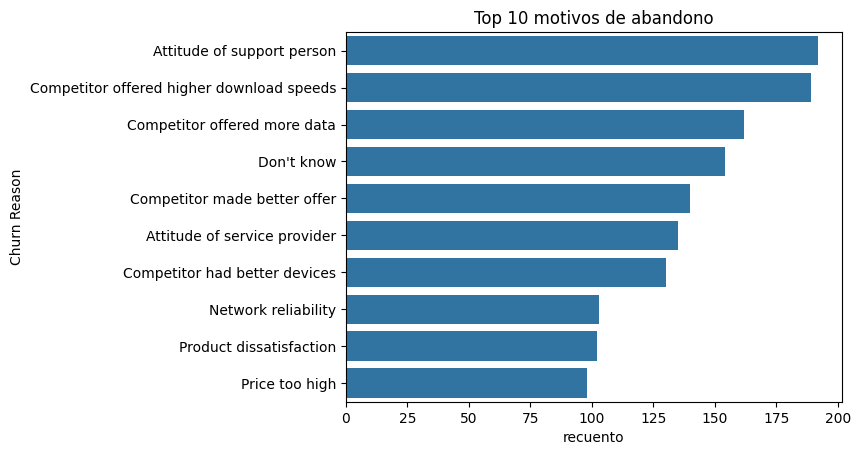

In [27]:
sns.barplot(data = agrupacion, y = 'Churn Reason', x = 'recuento')
plt.title('Top 10 motivos de abandono')
plt.show()

En el gráfico de top 10 de motivos principales de abandono encontramos como principal la actitud de la persona de atención de atención al cliente (lo cual puede indicar un área importante a mejorar o a tomar medidas) y además tres de las cinco principales razones están relacionadas con prestaciones de la competencia, lo que puede indicar puntos débiles de la compañía. 

In [28]:
recuento_ciudades_con_mas_clientes = churn.groupby(['City']).agg(recuento_clientes = ('CustomerID', 'count')).reset_index().nlargest(20,columns='recuento_clientes')
lista_ciudades = list(recuento_ciudades_con_mas_clientes['City'].unique())
recuento_ciudades_con_mas_clientes

,City,recuento_clientes
562,Los Angeles,305
869,San Diego,150
878,San Jose,112
855,Sacramento,108
872,San Francisco,104
354,Fresno,64
556,Long Beach,60
702,Oakland,52
972,Stockton,44
56,Bakersfield,40


In [29]:
churn_grafico = churn[churn['City'].isin(lista_ciudades)]

Análisis de los clientes que se van y se quedan de las 30 ciudades con mas clientes

<Axes: xlabel='count', ylabel='City'>

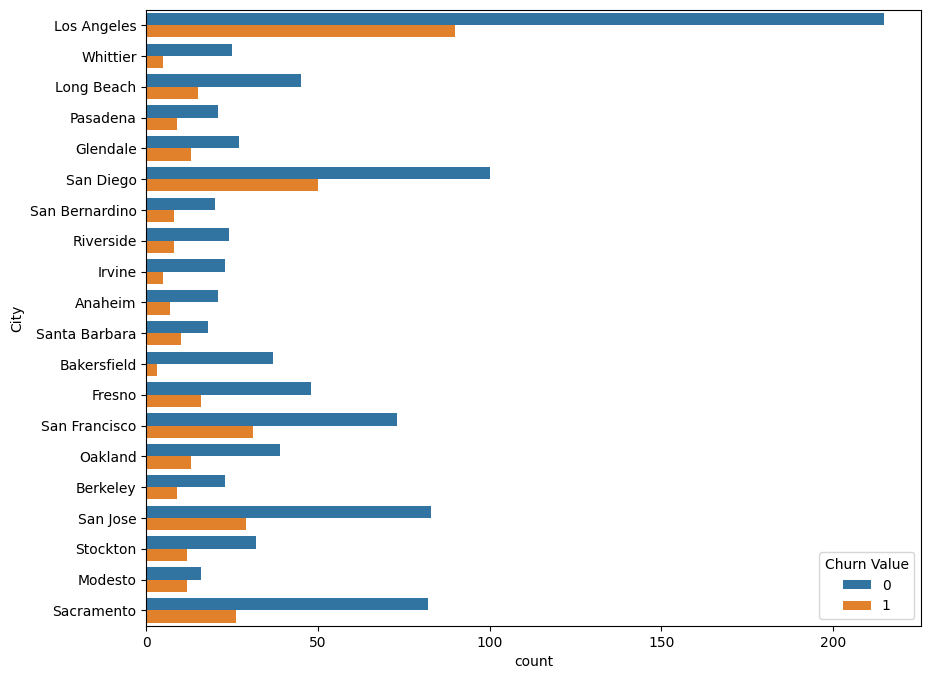

In [30]:
plt.figure(figsize = (10,8))
sns.countplot(data = churn_grafico, y = 'City', hue='Churn Value')
# plt.xticks(rotation = 45)

 El  gráfico  muestra que las ciudades con más clientes (Los Ángeles, San Diego, San José, Sacramento y San Francisco) son también las que tienen más abandonos, simplemente  por cantidad de población. En todas las ciudades hay más clientes que se quedan que clientes que se van, pero algunas como San Diego o Los Ángeles destacan por tener un alto número de bajas. A continuación, calcularemos qué ciudades tienen más proporción de gente que se va.

Análisis de la proporción de abandono dentro de las 20 ciudades con mas clientes 

In [31]:
total = churn.groupby('City').agg(total = ('CustomerID','count')).reset_index()
total

,City,total
0,Acampo,4
1,Acton,4
2,Adelanto,5
3,Adin,4
4,Agoura Hills,5
...,...,...
1124,Yreka,4
1125,Yuba City,8
1126,Yucaipa,4
1127,Yucca Valley,5


In [32]:
clientes_que_se_van = churn[churn['Churn Value'] == 1]

In [33]:
agrupacion_Se_van = clientes_que_se_van.groupby('City').agg(se_van = ('CustomerID','count')).reset_index()
total
agrupacion_Se_van

,City,se_van
0,Acampo,3
1,Adelanto,1
2,Adin,2
3,Agoura Hills,2
4,Aguanga,1
...,...,...
828,Yorkville,1
829,Yosemite National Park,2
830,Yuba City,2
831,Yucaipa,1


In [34]:
total = total.merge(agrupacion_Se_van, how = 'left',left_on='City', right_on = 'City')
total['proporcion'] = (total['se_van']/total['total']) * 100


In [35]:
total = total[total['City'].isin(lista_ciudades)].sort_values(by='proporcion',ascending = False)

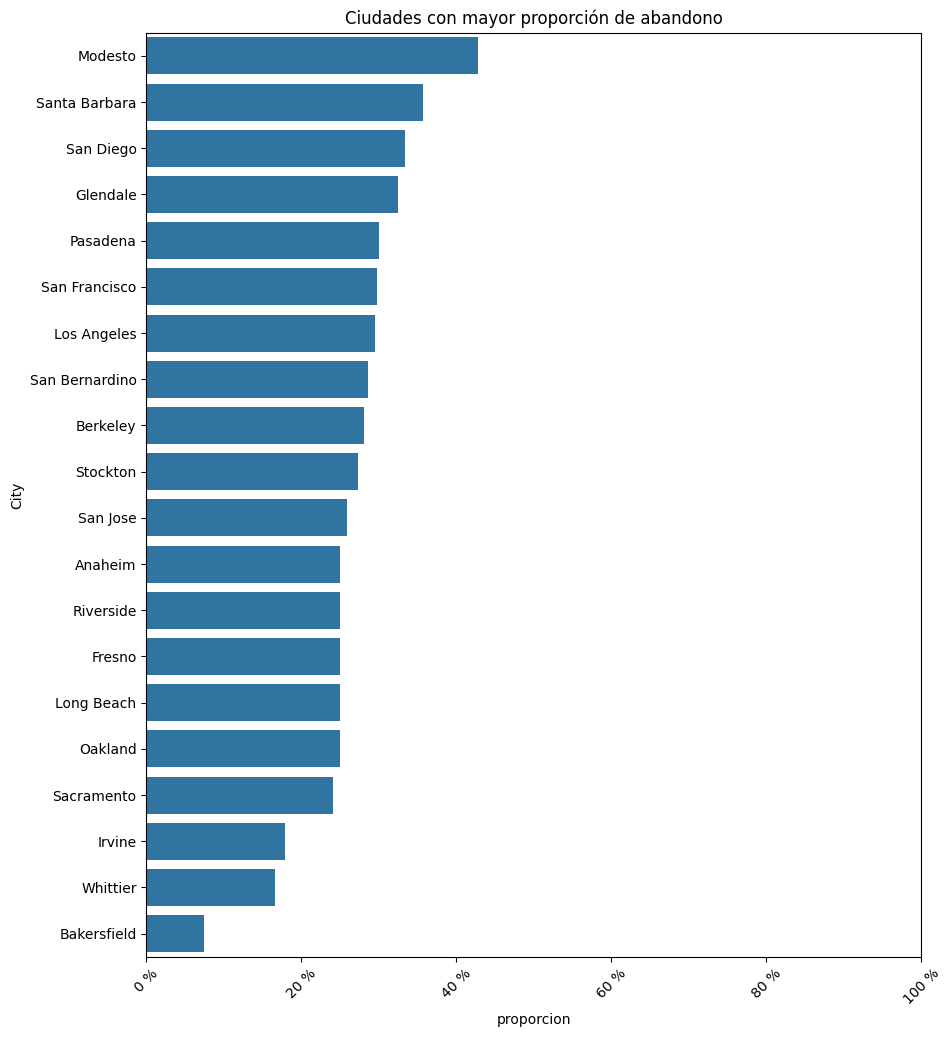

In [36]:
plt.figure(figsize = (10,12))
sns.barplot(data = total, x = 'proporcion', y='City', estimator='sum')
plt.title('Ciudades con mayor proporción de abandono')
plt.xticks([0, 20, 40, 60, 80, 100])
plt.gca().set_xticklabels(["0 %", "20 %", "40 %", "60 %", "80 %", "100 %"])
plt.xticks(rotation = 45)
plt.show()

El gráfico muestra qué ciudades tienen  mayor proporción de clientes que abandonan. Modesto y Santa Bárbara son las que presentan mayor proporción. En estas ciudades el riesgo de abandono es claramente superior a la media. Este análisis representa donded está realmente concentrado el problema del churn, independientemente del tamaño de cada ciudad

In [37]:
columas_para_histograma = ['Gender',
       'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges','Churn Score', 'CLTV']

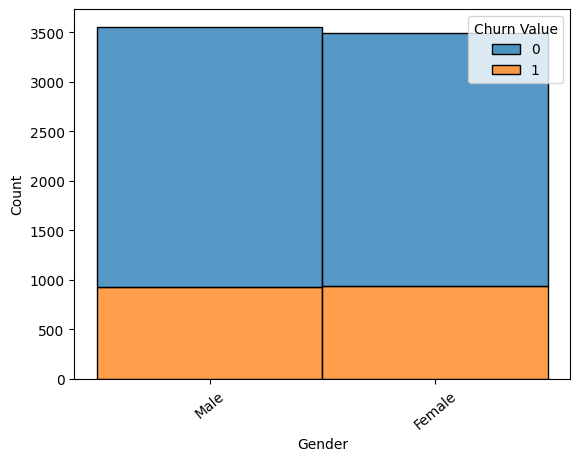

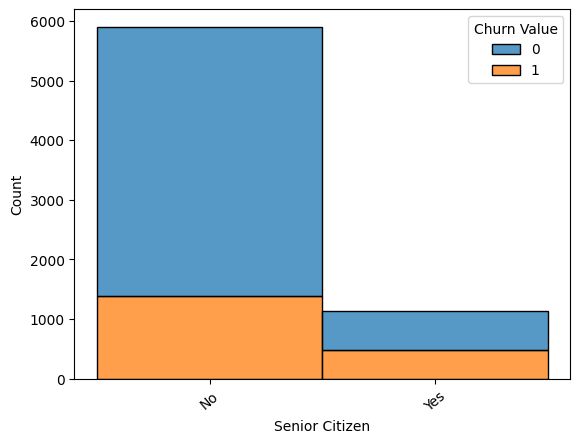

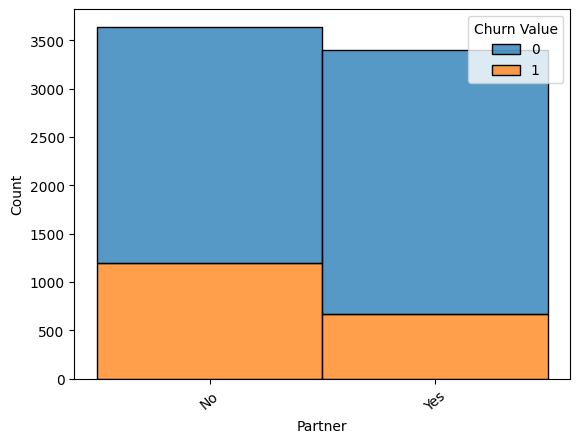

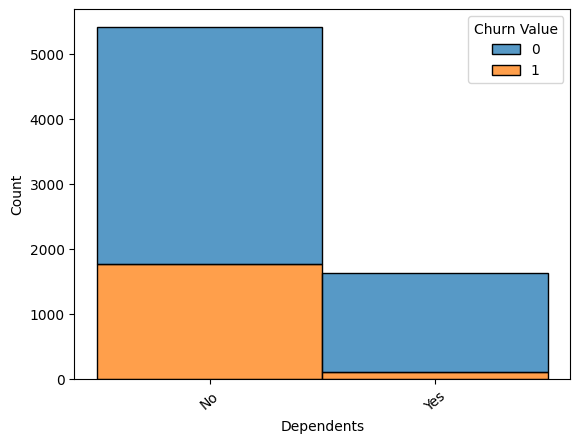

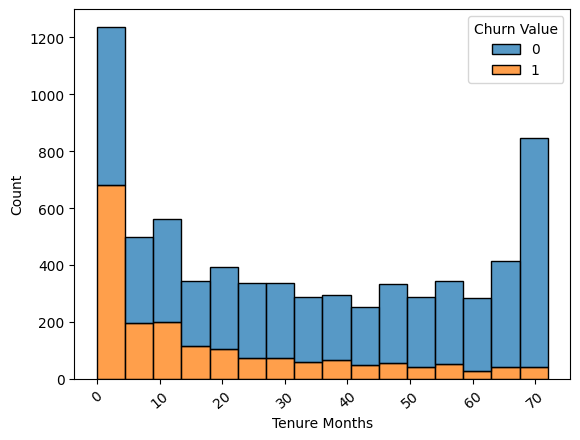

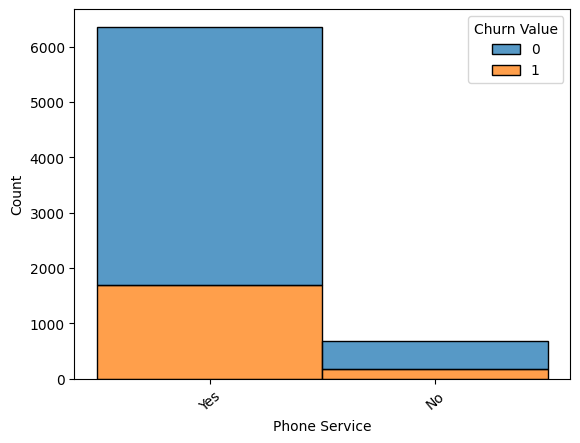

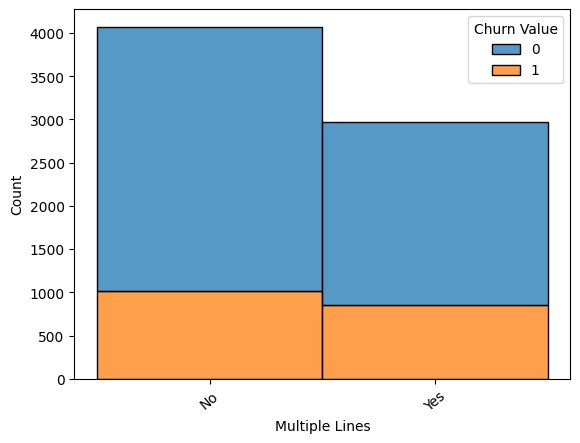

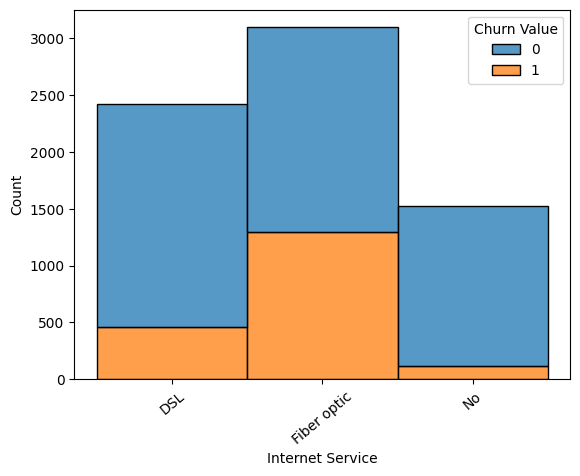

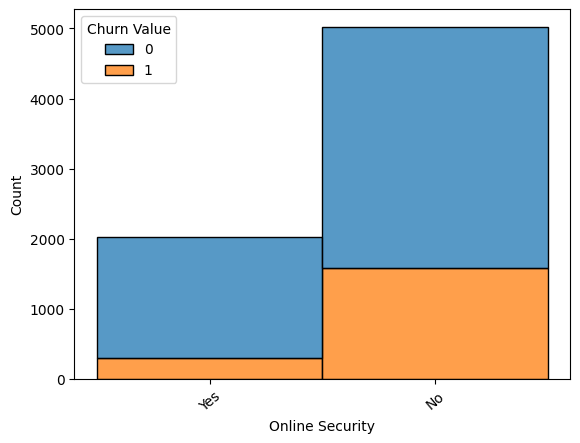

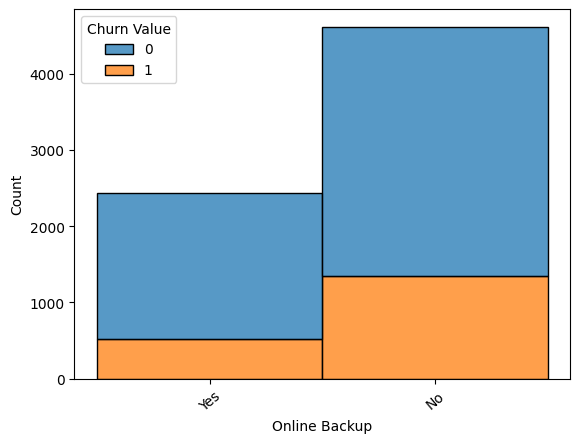

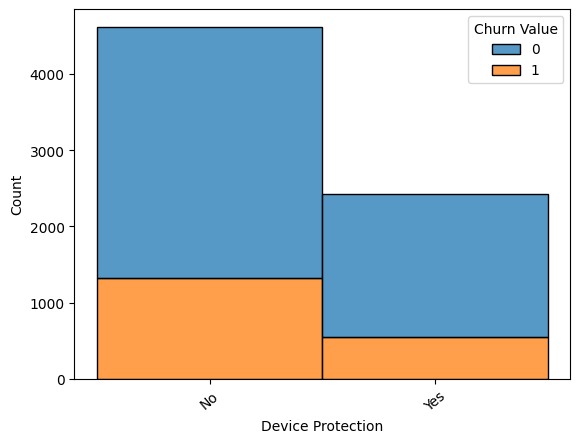

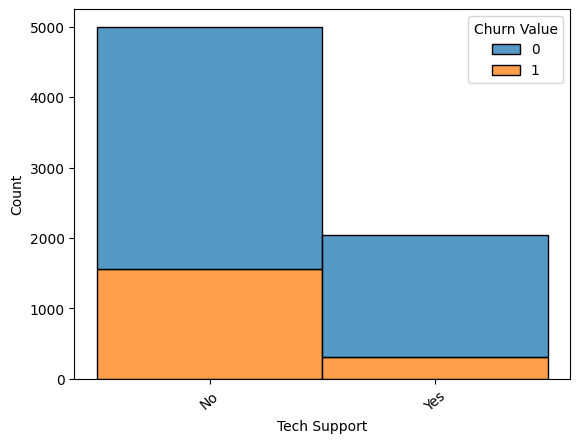

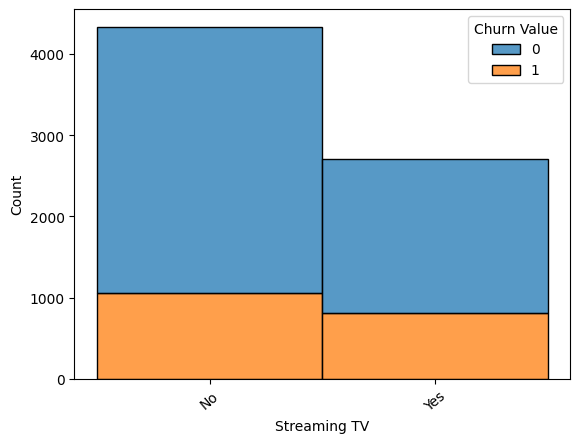

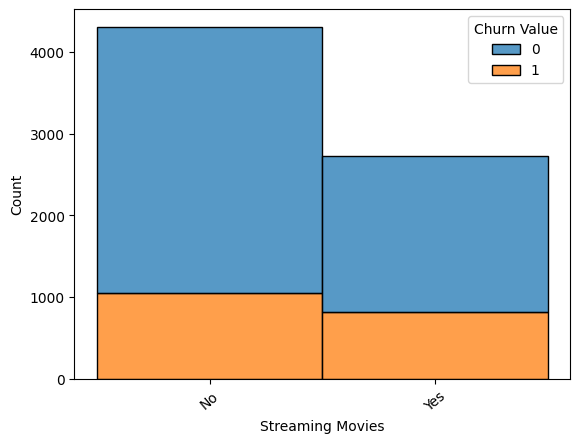

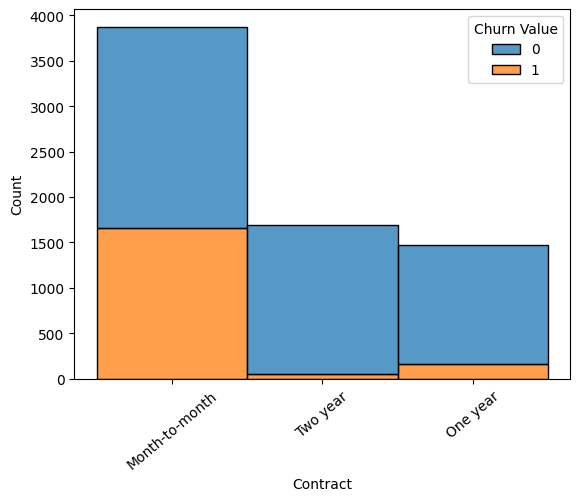

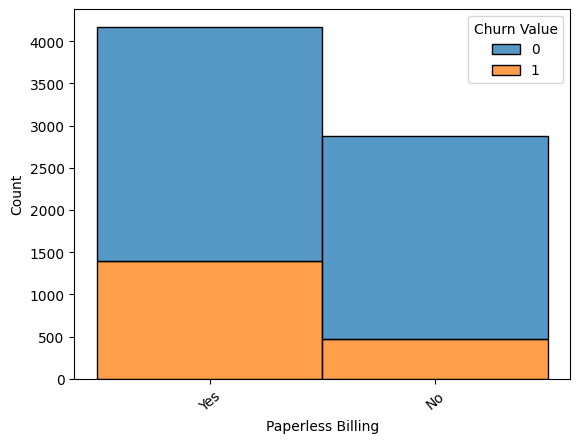

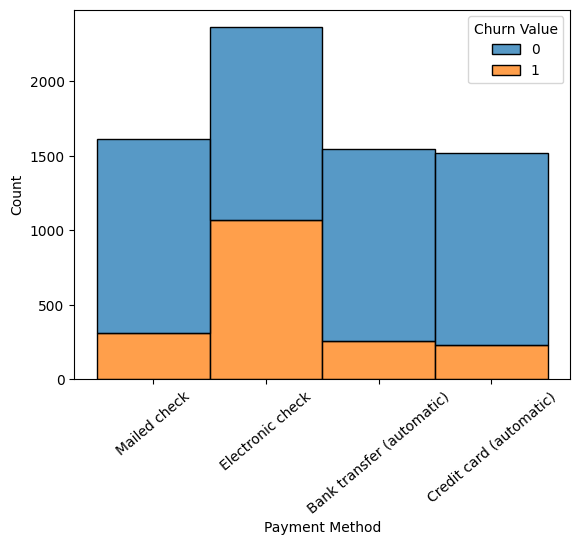

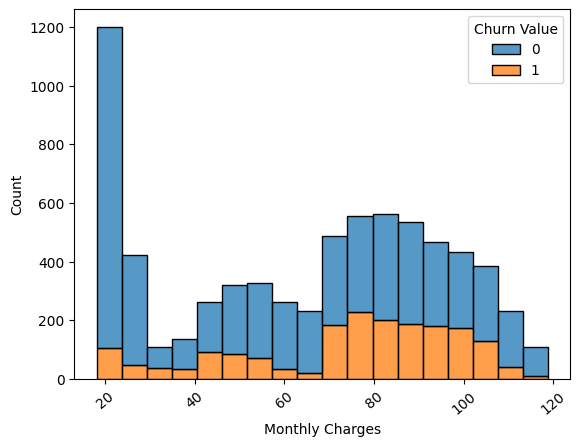

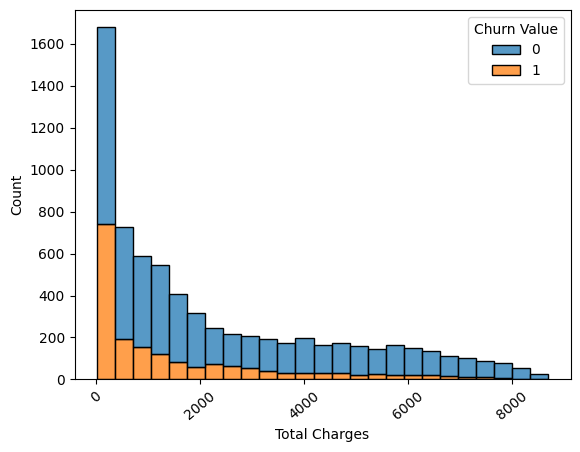

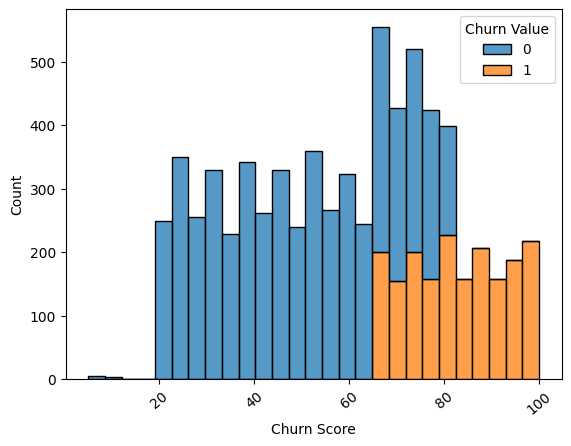

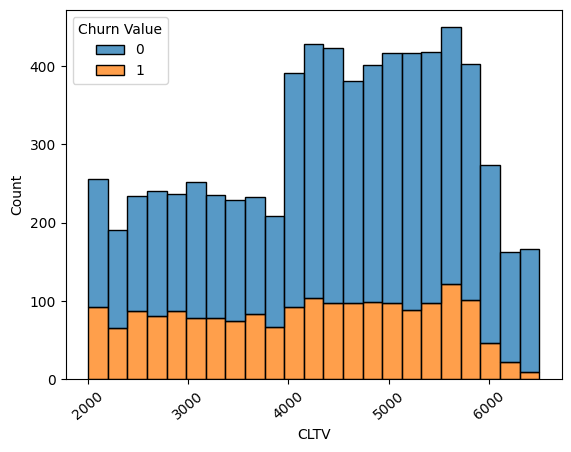

In [38]:
for n in columas_para_histograma:
    sns.histplot(data = churn, x = n, hue = churn['Churn Value'],multiple="stack")
    plt.xticks(rotation = 40)
    plt.show()

Los gráficos muestran que el churn es en proporción más común en clientes mayores, sin pareja , sin dependientes, y en personas que llevan poco tiempo en la empresa.  Los usuarios que no contratan servicios adicionales también presentan tasas de abandono más altas.

En cuanto al servicio, los clientes con interrnet muestran más probabilidades de irse. Además, el tipo de contrato es clave, ya que los clientes con el month-to-month contract son los que más abandonan la empresa, mientras que los contratos anuales retienen mucho mejor a los clientees. También se observa un mayor churn entre quienes usan facturación electrónica y pagan con electronic check. Además en el histograma del tipo de servicio de internet contratado se observa que la proporción de los clientes que abandonan es especialmente alta para los que contratan fibra óptica, lo que puede indicar un punto débil de la compañía o fuerte de la competencia.

En cuanto a los clientes con cuotas mensuales altas, estos abandonan más, mientras que los que tienen total charges bajos suelen corresponder a clientes nuevos que se marchan pronto. 

Por último, el churn score y el CLTV confirman que los clientes con scoring alto y valor medio-alto presentan un mayor riesgo de abandono.

-----
# Plan de acción basado en los patrones encontrados:

* Programa Onboarding inicial: Para mitigar el alto riesgo de abandono (churn) en los clientes con baja antigüedad (Tenure Months), es fundamental transformar la fase inicial del cliente para garantizar una experiencia inicial fluida y resolver proactivamente cualquier fricción o duda a través de un seguimiento de alto contacto  y con posibles incentivos de permanencia como "hitos semestrales" que favorezcan la fidelización y la estancia a largo plazo.

* Auditoría de atención al cliente: El hecho de que la principal razón de abandono esté relacionada con la atención al cliente es preocupante por lo que conviene llevar a cabo una auditoría en este departamento que pase por realizar grabaciones y analizar las interacciones de atención al cliente y llevar a cabo una capacitación intensiva al personal. Invertir en coaching centrado en habilidades blandas como empatía, o resolución de conflictos y habilidades técnicas para asegurar que el personal de soporte sea capaz de solucionar los problemas de los clientes. Además sería conveniente implementar métricas de satisfacción como encuestas post-interacción.

* Monitoreo Prioritario: Utilizar el churn score para crear una lista de clientes de alto valor (CLTV) con alto riesgo de abandono y asignar a estos clientes a un equipo de retención especializado con ofertas de fidelización superiores. Además la proporción de personas mayores que abandonan frente a la proporción de mayores que se quedan es superior por lo que son un segmento al que prestar especial atención. 

* Investigación de calidad de los servicios técnicos: Teniendo en cuenta que la proporción de bajas es alta para el servicio de internet de Fibra óptica, podría haber problemas de estabilidad, velocidad real, o precio. Por lo que habría que investigar las quejas específicas de estos clientes y comprobar y evaluar la calidad de este servicio.

* Comparativa competitiva: Tres de las cinco razones principales de abandono tienen que ver con las prestaciones de la competencia, por lo que es recomendable analizar el precio y las prestaciones de la fibra óptica de la competencia para ajustar la oferta o mejorar el servicio.


# (A partir de aquí son pruebas que hemos hecho con modelos que nos han ayudado a comprobar que el dataset es 'utilizable' y estaba limpio.)

In [39]:

y = churn["Churn Label"]

numeric_columns = ['CLTV', 'Total Charges', 'Monthly Charges', 'Tenure Months']
categorical_features = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method"
]
features = [
    "Gender", "Senior Citizen", "Partner",
    "Dependents", "Tenure Months",
    "Phone Service", "Multiple Lines",
    "Internet Service", "Online Security",
    "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV",
    "Streaming Movies", "Contract",
    "Paperless Billing", "Payment Method",
    "Monthly Charges", "Total Charges", "CLTV"
]
X = churn[features].copy()

#Aseguramos que son de tipo numérico

X[numeric_columns] = X[numeric_columns].apply(pd.to_numeric, errors='coerce')

for column in categorical_features: 

    X[column] =  LabelEncoder().fit_transform(X[column])
    
X[numeric_columns] = StandardScaler().fit_transform(X[numeric_columns])

In [40]:
for col in features:
    print(f"Columna: '{col}' | Valores únicos codificados: {X[col].unique()}")

Columna: 'Gender' | Valores únicos codificados: [1 0]
Columna: 'Senior Citizen' | Valores únicos codificados: [0 1]
Columna: 'Partner' | Valores únicos codificados: [0 1]
Columna: 'Dependents' | Valores únicos codificados: [0 1]
Columna: 'Tenure Months' | Valores únicos codificados: [-1.23672422 -0.99240204 -0.17799476  0.67713287 -0.91096131 -1.27744458
  0.59569215 -0.62591876 -1.11456313  0.06632742 -0.87024095 -0.70735949
 -0.5851984  -0.95168167 -1.0331224  -0.82952058 -0.30015585  1.45081979
  0.92145506  0.18848851 -1.19600386 -0.21871513 -0.50375767 -1.15528349
  1.04361615  0.84001433 -0.78880022 -1.07384277 -0.54447804  1.08433651
 -0.66663913  0.79929397 -0.34087622 -0.01511331  0.22920887  0.88073469
  0.43281069  1.24721797 -0.46303731  1.49154015 -0.42231695  1.16577724
  1.12505688  0.63641251  0.3106496  -0.38159658  0.26992924  0.10704778
  0.96217542  1.32865869  0.02560706 -0.09655404  0.51425142  0.55497178
  1.2064976   1.53226051  0.71785324  0.47353106  1.5729808

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,     
    random_state=42,   
    stratify=y        
)
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(5282, 20) (1761, 20)
(5282,) (1761,)


In [42]:
Regresion_Logistica = LogisticRegression(random_state = 42, max_iter = 10000)
Regresion_Logistica.fit(X_train, y_train)

y_pred_logistic = Regresion_Logistica.predict(X_test)

y_proba = Regresion_Logistica.predict_proba(X_test)
print(y_proba)

[[0.79274803 0.20725197]
 [0.97978891 0.02021109]
 [0.97988142 0.02011858]
 ...
 [0.85440509 0.14559491]
 [0.76419632 0.23580368]
 [0.45116618 0.54883382]]


In [43]:
accuracy = accuracy_score(y_test, y_pred_logistic)
print(f"Accuracy:   {accuracy * 100}%")

Accuracy:   81.43100511073254%


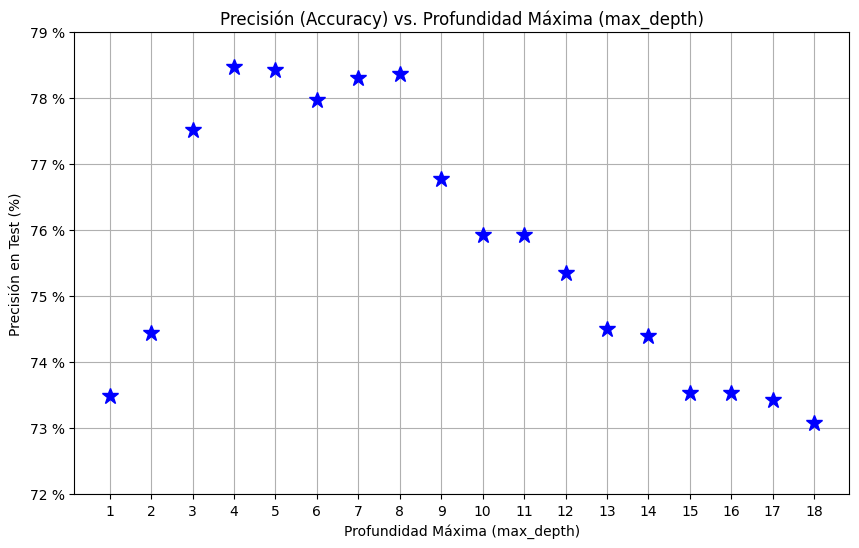

In [44]:
#TEST DE ÁRBOLES CON DISTINTAS max_depth

lista_depth = range(1, 19) 
plt.figure(figsize=(10, 6)) 
depths = []
accuracies = []
for i in lista_depth:
    
    arbol = DecisionTreeClassifier(
        random_state=42,   
        max_depth= i
    )
    arbol.fit(X_train, y_train)
    y_pred_tree = arbol.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred_tree) * 100
    
    plt.plot(i, accuracy, marker='*', linestyle='-', color='b', markersize = 12)
    # print("Arbol con  profundidad: ", i)
    # print(f"ACCURACY:   \t {accuracy}%\n")

plt.title('Precisión (Accuracy) vs. Profundidad Máxima (max_depth)')
plt.xlabel('Profundidad Máxima (max_depth)')
plt.ylabel('Precisión en Test (%)')
plt.yticks(range(72,80))
plt.xticks(range(1,19))
plt.grid()
plt.gca().set_yticklabels(["72 %", "73 %", "74 %", "75 %", "76 %", "77 %", "78 %", "79 %"])
plt.show()

# TRATAMIENTO DE VARIABLES

Primero vamos a ver que variables meter al modelo empezando por comprobar si meter City realmente aporta y probando con un modelo sencillo de regresión logística y comparando resultados haciendo feature selection automática.

Después vamos a probar a aplicar técnicas de reducción de dimensionalidad y comparar resultados para ver si es conveniente o no.

In [45]:
columnas_a_codificar = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method", 'Churn Label'
]

label_encoder = LabelEncoder()

for columna in columnas_a_codificar:


    churn[columna] = label_encoder.fit_transform(churn[columna])


In [46]:
# Se ha hecho onehot encoding porque si usamos labelencoding normal los modelos como la regresion logistica pueden interpretar ordinalidad 
# entre las ciudades 'Los Angeles' 256 y San Mateo 987.  

churn = pd.get_dummies(churn, columns=['City'], prefix='City')
churn

,CustomerID,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,...,City_Yermo,City_Yorba Linda,City_Yorkville,City_Yosemite National Park,City_Yountville,City_Yreka,City_Yuba City,City_Yucaipa,City_Yucca Valley,City_Zenia
0,3668-QPYBK,1,0,0,0,2,1,0,0,1,...,False,False,False,False,False,False,False,False,False,False
1,9237-HQITU,0,0,0,1,2,1,0,1,0,...,False,False,False,False,False,False,False,False,False,False
2,9305-CDSKC,0,0,0,1,8,1,1,1,0,...,False,False,False,False,False,False,False,False,False,False
3,7892-POOKP,0,0,1,1,28,1,1,1,0,...,False,False,False,False,False,False,False,False,False,False
4,0280-XJGEX,1,0,0,1,49,1,1,1,0,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,2569-WGERO,0,0,0,0,72,1,0,2,0,...,False,False,False,False,False,False,False,False,False,False
7039,6840-RESVB,1,0,1,1,24,1,1,0,1,...,False,False,False,False,False,False,False,False,False,False
7040,2234-XADUH,0,0,1,1,72,1,1,1,0,...,False,False,False,False,False,False,False,False,False,False
7041,4801-JZAZL,0,0,1,1,11,0,0,0,1,...,False,False,False,False,False,False,False,False,False,False


In [47]:
columnas_a_escalar = [
"Total Charges", 'Monthly Charges', 'Tenure Months','CLTV'
]

scaler = StandardScaler()

churn[columnas_a_escalar] = scaler.fit_transform(churn[columnas_a_escalar])

In [ ]:
Y = churn['Churn Label']
X_con_city = churn.drop(columns=['Churn Label','CustomerID', 'Churn Value', 'Churn Label',  'Churn Reason','Churn Score'], axis=1)
print(Y.shape)
print(X_con_city.shape)


(7043,)
(7043, 20)


Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'CLTV'],
      dtype='object')

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X_con_city, Y, test_size=0.3, random_state=42,stratify=Y)

In [50]:
#REGRESION LOGISTICA CON CITY METIDO

logistica = LogisticRegression()
logistica.fit(X_train, y_train)

proba_log = logistica.predict_proba(X_test)[:, 1]
print(proba_log)

y_pred_logistic = logistica.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_logistic)
print(f"Accuracy:   {accuracy * 100}%")
auc_log = roc_auc_score(y_test, proba_log)
print(f"Logistic Regression AUC: {auc_log}")
recall = recall_score(y_test, y_pred_logistic)
print(f"recall:   {recall * 100}%")
test_classification_rep = classification_report(y_test, y_pred_logistic)
print("\nTest classification Report:\n", test_classification_rep)

[0.65961359 0.01712668 0.86634494 ... 0.03632809 0.7273874  0.02009644]
Accuracy:   79.08187411263606%
Logistic Regression AUC: 0.8424343495598801
recall:   55.43672014260249%

Test classification Report:
               precision    recall  f1-score   support

           0       0.84      0.88      0.86      1552
           1       0.62      0.55      0.58       561

    accuracy                           0.79      2113
   macro avg       0.73      0.72      0.72      2113
weighted avg       0.78      0.79      0.79      2113



In [77]:
churn = churn.iloc[:, :25] 
Y = churn['Churn Label']
X = churn.drop(columns=['Churn Label','CustomerID', 'Churn Value',  'Churn Reason','Churn Score'], axis=1)
X

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,CLTV
0,1,0,0,0,-1.236724,1,0,0,1,1,0,0,0,0,0,1,3,-0.362660,-0.959674,-0.981675
1,0,0,0,1,-1.236724,1,0,1,0,0,0,0,0,0,0,1,2,0.197365,-0.940470,-1.436462
2,0,0,0,1,-0.992402,1,1,1,0,0,1,0,1,1,0,1,2,1.159546,-0.645186,0.821409
3,0,0,1,1,-0.177995,1,1,1,0,0,1,1,1,1,0,1,2,1.330711,0.337349,0.509483
4,1,0,0,1,0.677133,1,1,1,0,1,1,0,1,1,0,1,0,1.294151,1.216004,0.794358
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,0,0,0,1.613701,1,0,2,0,0,0,0,0,0,2,1,0,-1.449476,-0.380784,0.765617
7039,1,0,1,1,-0.340876,1,1,0,1,0,1,1,1,1,1,1,3,0.665992,-0.128655,-1.910691
7040,0,0,1,1,1.613701,1,1,1,0,1,1,0,1,1,1,1,1,1.277533,2.243151,0.980330
7041,0,0,1,1,-0.870241,0,0,0,1,0,0,0,0,0,0,1,2,-1.168632,-0.854469,-1.358692


In [80]:
X.columns == X_con_city.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True])

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42,stratify=Y)

In [53]:
#REGRESION LOGISTICA SIN CITY METIDO
logistica = LogisticRegression(class_weight='balanced')
logistica.fit(X_train, y_train)

proba_log = logistica.predict_proba(X_test)[:, 1]
print(proba_log)

y_pred_logistic = logistica.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_logistic)
print(f"Accuracy:   {accuracy * 100}%")
auc_log = roc_auc_score(y_test, proba_log)
print(f"Logistic Regression AUC: {auc_log}")
recall = recall_score(y_test, y_pred_logistic)
print(f"recall:   {recall * 100}%")
test_classification_rep = classification_report(y_test, y_pred_logistic)
print("\nTest classification Report:\n", test_classification_rep)

[0.80226083 0.03030725 0.87192172 ... 0.13722408 0.80684281 0.06528161]
Accuracy:   74.68054898248934%
Logistic Regression AUC: 0.8521383483102707
recall:   80.21390374331551%

Test classification Report:
               precision    recall  f1-score   support

           0       0.91      0.73      0.81      1552
           1       0.51      0.80      0.63       561

    accuracy                           0.75      2113
   macro avg       0.71      0.76      0.72      2113
weighted avg       0.81      0.75      0.76      2113



Como era de esperar la predicción en general sale un poco mejor sin city, entonces no la vamos a incluir de primeras. Para el resto de variables vamos a probar a ver si hay diferencias entre poner o quitar unas u otras usando la funcion de feature selection. 

# Feature selection

In [54]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import classification_report, recall_score

# --- 1. Definir modelo base ---
logistic = LogisticRegression(
    random_state=42,
    max_iter=500,
    class_weight='balanced'
)

# --- 2. Configurar Sequential Feature Selector ---
sfs = SequentialFeatureSelector(
    estimator=logistic,
    n_features_to_select='auto',   # deja que el SFS elija el número óptimo
    direction='forward',           # forward o backward
    scoring='f1',                  # métrica a optimizar (clase 1)
    cv=5,                          # cross-validation
    n_jobs=-1
)

print("Ejecutando Sequential Feature Selection (SFS)...")
sfs.fit(X_train, y_train)
print("¡SFS completado!")

# --- 3. Obtener columnas seleccionadas ---
selected_columns = X_train.columns[sfs.get_support()]
print(f"Columnas seleccionadas ({len(selected_columns)}):")
print(selected_columns.tolist())

# --- 4. Filtrar datasets con columnas seleccionadas ---
X_train_sfs = X_train.loc[:, selected_columns]
X_test_sfs  = X_test.loc[:, selected_columns]

# --- 5. Entrenar modelo final ---
logistic.fit(X_train_sfs, y_train)

# --- 6. Evaluar en test ---
y_pred = logistic.predict(X_test_sfs)

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))

final_recall = recall_score(y_test, y_pred)
print(f"Recall clase 1 en test: {final_recall:.4f}")

Ejecutando Sequential Feature Selection (SFS)...
¡SFS completado!
Columnas seleccionadas (10):
['Gender', 'Senior Citizen', 'Dependents', 'Internet Service', 'Tech Support', 'Streaming TV', 'Contract', 'Monthly Charges', 'Total Charges', 'CLTV']

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1552
           1       0.50      0.78      0.61       561

    accuracy                           0.74      2113
   macro avg       0.70      0.75      0.70      2113
weighted avg       0.79      0.74      0.75      2113

Recall clase 1 en test: 0.7754


Como se puede ver en este ejemplo, aplicando la funcion sequentialfeatures quedándonos con las 10 variables que más aportan a la maximizacion del f1 las predicciones en test son peores que con respecto a la regresion logistica normal con todas las features (excepto city, que hemos descartado)

# Reducción de dimensiones

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42,stratify=Y)

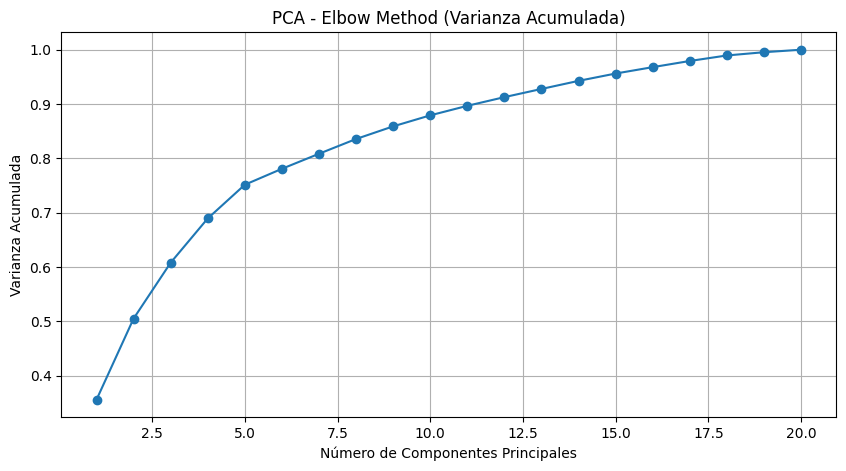

In [56]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Ajustar PCA completo (tantos componentes como variables tengas)
pca_full = PCA().fit(X_train)

# Varianza individual y acumulada
var_exp = pca_full.explained_variance_ratio_
var_exp_cum = np.cumsum(var_exp)
plt.figure(figsize=(10,5))
plt.plot(range(1, len(var_exp_cum) + 1), var_exp_cum, marker='o')
plt.title("PCA - Elbow Method (Varianza Acumulada)")
plt.xlabel("Número de Componentes Principales")
plt.ylabel("Varianza Acumulada")
plt.grid(True)
plt.show()

In [82]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. PCA ---
pca = PCA(n_components=13)  # 13 componentes principales
pca.fit(X_train)             # ajustar solo con train

X_train_pca = pca.transform(X_train)
X_test_pca  = pca.transform(X_test)

print("Varianza total capturada por las 13 componentes:", np.sum(pca.explained_variance_ratio_))

# --- 2. Regresión Logística ---
logistica = LogisticRegression(class_weight='balanced', random_state=42, max_iter=500)
logistica.fit(X_train_pca, y_train)

# --- 3. Predicciones ---
y_test_pred  = logistica.predict(X_test_pca)
y_test_proba = logistica.predict_proba(X_test_pca)[:, 1]

# --- 4. Métricas principales ---
accuracy  = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall    = recall_score(y_test, y_test_pred)
f1        = f1_score(y_test, y_test_pred)
auc       = roc_auc_score(y_test, y_test_proba)

print("\n=== MÉTRICAS EN TEST ===")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"AUC       : {auc:.4f}")

# --- 5. Reporte detallado ---
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_test_pred))


Varianza total capturada por las 13 componentes: 0.9277901524585191

=== MÉTRICAS EN TEST ===
Accuracy  : 0.7345
Precision : 0.5000
Recall    : 0.7950
F1-score  : 0.6139
AUC       : 0.8352

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1552
           1       0.50      0.80      0.61       561

    accuracy                           0.73      2113
   macro avg       0.70      0.75      0.71      2113
weighted avg       0.80      0.73      0.75      2113



In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Definir y entrenar el modelo ---
logistica = LogisticRegression(
    random_state=42,
    max_iter=500,
    class_weight='balanced'  # útil si hay desbalance de clases
)
logistica.fit(X_train, y_train)

# --- 2. Predicciones ---
y_test_pred  = logistica.predict(X_test)
y_test_proba = logistica.predict_proba(X_test)[:, 1]  # probabilidad de clase 1

# --- 3. Métricas principales ---
accuracy  = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall    = recall_score(y_test, y_test_pred)
f1        = f1_score(y_test, y_test_pred)
auc       = roc_auc_score(y_test, y_test_proba)

print("\n=== MÉTRICAS EN TEST ===")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"AUC       : {auc:.4f}")

# --- 4. Reporte detallado ---
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_test_pred))




=== MÉTRICAS EN TEST ===
Accuracy  : 0.7468
Precision : 0.5149
Recall    : 0.8021
F1-score  : 0.6272
AUC       : 0.8521

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1552
           1       0.51      0.80      0.63       561

    accuracy                           0.75      2113
   macro avg       0.71      0.76      0.72      2113
weighted avg       0.81      0.75      0.76      2113



Como se puede observar con el elbow method, se requieren casi 13 componentes para captar el 90% de la varianza, cosa que ya conseguíamos con el x_train normal, como además empeora ligeramente la predicción lo mejor será no aplicar pca ni otras técnicas de reducción de dimensonalidad.

# TÉCNICAS DE DESBALANCEO

In [ ]:
# PRIMERO SE SEPARA EN TRAIN TEST SPLIT Y LUEGO SE APLICA DESBALANCEO SOBRE EL CONJUNTO DE TRAIN
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42,stratify=Y, shuffle=True)

In [60]:
print("Distribución original:", Counter(y_train))

rus = RandomUnderSampler(random_state=42, sampling_strategy=1)
X_under, y_under = rus.fit_resample(X_train, y_train)
# Modificar el sampling strategy para bajar más o menos la cantidad de datos de la clase 0 hasta igualar la 1.
# A medida que el sampling strategy baja, baja la disminución de datos de la clase dominante 
print("Distribución tras under-sampling:", Counter(y_under))

Distribución original: Counter({0: 3622, 1: 1308})
Distribución tras under-sampling: Counter({0: 1308, 1: 1308})


In [61]:
print("Distribución original:", Counter(y_train))

ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X_train, y_train)
# Modificar el sampling strategy para subir más o menos la cantidad de datos de la clase 1 hasta igualar la 0.
# A medida que el sampling strategy baja, baja el aumento de datos de la clase minoritaria. 
print("Distribución tras over-sampling:", Counter(y_over))

Distribución original: Counter({0: 3622, 1: 1308})
Distribución tras over-sampling: Counter({0: 3622, 1: 3622})


In [62]:

print("Distribución original:", Counter(y_train))

smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X_train, y_train)

print("Distribución tras SMOTE:", Counter(y_smote))

Distribución original: Counter({0: 3622, 1: 1308})
Distribución tras SMOTE: Counter({0: 3622, 1: 3622})


Prueba 1 REGRESION SIN BALANCEO DE DATOS

In [63]:
#Esta regresión es para probar los efectos en la regresion logistica sin ajuste con los datos balanceados creados arriba

logistica = LogisticRegression()
logistica.fit(X_train, y_train)

proba_log = logistica.predict_proba(X_test)[:, 1]
print(proba_log)

y_pred_logistic = logistica.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_logistic)
print(f"Accuracy:   {accuracy * 100}%")
auc_log = roc_auc_score(y_test, proba_log)
print(f"Logistic Regression AUC: {auc_log}")
recall = recall_score(y_test, y_pred_logistic)
print(f"recall:   {recall * 100}%")
test_classification_rep = classification_report(y_test, y_pred_logistic)
print("\nTest classification Report:\n", test_classification_rep)

[0.60501975 0.01207909 0.72634989 ... 0.04893852 0.60797153 0.02443138]
Accuracy:   81.02224325603407%
Logistic Regression AUC: 0.8524208886928717
recall:   59.893048128342244%

Test classification Report:
               precision    recall  f1-score   support

           0       0.86      0.89      0.87      1552
           1       0.66      0.60      0.63       561

    accuracy                           0.81      2113
   macro avg       0.76      0.74      0.75      2113
weighted avg       0.81      0.81      0.81      2113



Prueba 2 REGRESIÓN SIN DATOS BALANCEADOS PERO CON PARÁMETRO 'CLASS_WEIGHT' = BALANCED

In [64]:
# Regresion logistica sin balanceo de datos pero con class_weight 'balanced', se puede observar que ya mejora el recall y va bajando el accuracy general
logistica = LogisticRegression(class_weight='balanced')
logistica.fit(X_train, y_train)

proba_log = logistica.predict_proba(X_test)[:, 1]
print(proba_log)

y_pred_logistic = logistica.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_logistic)
print(f"Accuracy:   {accuracy * 100}%")
auc_log = roc_auc_score(y_test, proba_log)
print(f"Logistic Regression AUC: {auc_log}")
recall = recall_score(y_test, y_pred_logistic)
print(f"recall:   {recall * 100}%")
test_classification_rep = classification_report(y_test, y_pred_logistic)
print("\nTest classification Report:\n", test_classification_rep)

[0.80226083 0.03030725 0.87192172 ... 0.13722408 0.80684281 0.06528161]
Accuracy:   74.68054898248934%
Logistic Regression AUC: 0.8521383483102707
recall:   80.21390374331551%

Test classification Report:
               precision    recall  f1-score   support

           0       0.91      0.73      0.81      1552
           1       0.51      0.80      0.63       561

    accuracy                           0.75      2113
   macro avg       0.71      0.76      0.72      2113
weighted avg       0.81      0.75      0.76      2113



PRUEBA 3 REGRESION CON DATOS UNDERSAMPLEADOS

In [65]:
#Regresion logistica con datos undersampleados (se puede ajustar arriba el nivel de undersampleo, ahora mismo esta puesto en 1 así que baja la clase dominante hasta igualar a la clase minoritaria)
logistica = LogisticRegression()
logistica.fit(X_under, y_under)

proba_log = logistica.predict_proba(X_test)[:, 1]
print(proba_log)

y_pred_logistic = logistica.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_logistic)
print(f"Accuracy:   {accuracy * 100}%")
auc_log = roc_auc_score(y_test, proba_log)
print(f"Logistic Regression AUC: {auc_log}")
recall = recall_score(y_test, y_pred_logistic)
print(f"recall:   {recall * 100}%")
test_classification_rep = classification_report(y_test, y_pred_logistic)
print("\nTest classification Report:\n", test_classification_rep)

[0.79381625 0.02582963 0.887186   ... 0.17191609 0.78115734 0.06555077]
Accuracy:   74.53857075248462%
Logistic Regression AUC: 0.8502363691493467
recall:   80.74866310160428%

Test classification Report:
               precision    recall  f1-score   support

           0       0.91      0.72      0.81      1552
           1       0.51      0.81      0.63       561

    accuracy                           0.75      2113
   macro avg       0.71      0.77      0.72      2113
weighted avg       0.81      0.75      0.76      2113



PRUEBA 3 REGRESION CON DATOS OVERSAMPLEADOS

In [66]:
#Regresion logistica con datos oversampleados (se puede ajustar arriba el nivel de oversampleo, ahora mismo esta puesto en 1 así que sube la clase minoritaria hasta igualar a la clase dominante)
logistica = LogisticRegression()
logistica.fit(X_over, y_over)

proba_log = logistica.predict_proba(X_test)[:, 1]
print(proba_log)

y_pred_logistic = logistica.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_logistic)
print(f"Accuracy:   {accuracy * 100}%")
auc_log = roc_auc_score(y_test, proba_log)
print(f"Logistic Regression AUC: {auc_log}")
recall = recall_score(y_test, y_pred_logistic)
print(f"recall:   {recall * 100}%")
test_classification_rep = classification_report(y_test, y_pred_logistic)
print("\nTest classification Report:\n", test_classification_rep)

[0.81659484 0.03090831 0.87555329 ... 0.13720957 0.822126   0.06723024]
Accuracy:   74.77520113582584%
Logistic Regression AUC: 0.8522187459801165
recall:   80.57040998217468%

Test classification Report:
               precision    recall  f1-score   support

           0       0.91      0.73      0.81      1552
           1       0.52      0.81      0.63       561

    accuracy                           0.75      2113
   macro avg       0.71      0.77      0.72      2113
weighted avg       0.81      0.75      0.76      2113



PRUEBA 4 REGRESION CON DATOS SMOTEADOS

In [67]:

logistica = LogisticRegression()
logistica.fit(X_smote, y_smote)

proba_log = logistica.predict_proba(X_test)[:, 1]
print(proba_log)

y_pred_logistic = logistica.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_logistic)
print(f"Accuracy:   {accuracy * 100}%")
auc_log = roc_auc_score(y_test, proba_log)
print(f"Logistic Regression AUC: {auc_log}")
recall = recall_score(y_test, y_pred_logistic)
print(f"recall:   {recall * 100}%")
test_classification_rep = classification_report(y_test, y_pred_logistic)
print("\nTest classification Report:\n", test_classification_rep)

[0.81982792 0.01239313 0.76069104 ... 0.05617796 0.78574236 0.02737936]
Accuracy:   76.19498343587317%
Logistic Regression AUC: 0.8424894793906316
recall:   76.11408199643493%

Test classification Report:
               precision    recall  f1-score   support

           0       0.90      0.76      0.82      1552
           1       0.54      0.76      0.63       561

    accuracy                           0.76      2113
   macro avg       0.72      0.76      0.73      2113
weighted avg       0.80      0.76      0.77      2113



 smote mejora el accuracy pero empeora el recall, mientras que el under y el upper mejoran el recall y si usamos el train test split normal el accuracy es el mejor 81% pero el recall es el peor de todos los métodos

# PRUEBAS DE PIPELINES CON DIFERENTES MODELOS DE CLASIFICACIÓN + VALIDACION CRUZADA + GRID SEARCH + BALANCEO DE DATOS

A partir de aqui ya se implementa todo para cada modelo en un pipeline:

-Para el random forest y el xgboost se usa el grid search para la parametrización mientras que para Naive Bayes, Regresion logistica y Discriminante se usan modelos sin parámetros.

-Para todos los modelos se incluye un pipline que hace el balanceo de datos y la validación cruzada (importante: el pipeline se fitea con x_train porque dentro del mismo está incluido el balanceo, entonces por cada fold de validación cruzada se coge un trozo de x_train y se aplica el balanceo y así sucesivamente)

In [68]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import classification_report, recall_score
from sklearn.model_selection import GridSearchCV

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler


# 1. Pipeline con oversampling
pipeline_rf = ImbPipeline([
    ("UNDERsampler", RandomUnderSampler(random_state=42, sampling_strategy=1)),
    ("rf", RandomForestClassifier(random_state=42, class_weight="balanced"))
])

# 2. Definición del grid de hiperparámetros
param_grid = {
    "rf__n_estimators": [100, 200, 300],     # límite pedido
    "rf__max_depth": [2, 4, 6, 8]            # profundidad máxima 10

}

# 3. GridSearchCV optimizando recall
grid_search = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid,
    scoring="f1",
    cv=4,
    verbose=1
)

print("Ejecutando GridSearchCV...")
grid_search.fit(X_train, y_train)
print("GridSearch completo.")

print("\nMejores parámetros encontrados:")
print(grid_search.best_params_)

print(f"\nMejor score (Recall CV): {grid_search.best_score_:.4f}")


# ============================================================
#   FASE C — EVALUACIÓN FINAL EN TEST
# ============================================================

print("\n## 3. Fase C: Evaluación Final")
print("------------------------------")

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("\n=== REPORTE FINAL ===")
print(classification_report(y_test, y_pred))

final_recall = recall_score(y_test, y_pred)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando GridSearchCV...
Fitting 4 folds for each of 12 candidates, totalling 48 fits
GridSearch completo.

Mejores parámetros encontrados:
{'rf__max_depth': 8, 'rf__n_estimators': 100}

Mejor score (Recall CV): 0.6500

## 3. Fase C: Evaluación Final
------------------------------

=== REPORTE FINAL ===
              precision    recall  f1-score   support

           0       0.91      0.74      0.81      1552
           1       0.52      0.80      0.63       561

    accuracy                           0.75      2113
   macro avg       0.72      0.77      0.72      2113
weighted avg       0.81      0.75      0.77      2113

Recall Final en TEST: 0.8039


In [ ]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, recall_score
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

# 1. Pipeline con oversampling + XGBoost
pipeline_xgb = ImbPipeline([
    ("UNDERsampler", RandomUnderSampler(random_state=42, sampling_strategy=1)),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        use_label_encoder=False,
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Definición del grid de hiperparámetros
param_grid = {
    "xgb__n_estimators": [100, 200, 300],    # límite pedido
    "xgb__max_depth": [2, 4, 6, 8],          # profundidad máxima 10
    "xgb__learning_rate": [0.05, 0.1, 0.2],  # opcional para tunear
    "xgb__subsample": [0.8, 1.0],
    "xgb__colsample_bytree": [0.8, 1.0]
}

# 3. GridSearchCV optimizando f1
grid_search = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=param_grid,
    scoring="recall",
    cv=4,
    verbose=1,
    n_jobs=-1
)

print("Ejecutando GridSearchCV...")
grid_search.fit(X_train, y_train)
print("GridSearch completo.")

print("\nMejores parámetros encontrados:")
print(grid_search.best_params_)

print(f"\nMejor score (F1 CV): {grid_search.best_score_:.4f}")

# ============================================================
#   FASE C — EVALUACIÓN FINAL EN TEST
# ============================================================

print("\n## 3. Fase C: Evaluación Final")
print("------------------------------")

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("\n=== REPORTE FINAL ===")
print(classification_report(y_test, y_pred))

final_recall = recall_score(y_test, y_pred)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando GridSearchCV...
Fitting 4 folds for each of 144 candidates, totalling 576 fits
GridSearch completo.

Mejores parámetros encontrados:
{'xgb__colsample_bytree': 1.0, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 4, 'xgb__n_estimators': 100, 'xgb__subsample': 1.0}

Mejor score (F1 CV): 0.8341

## 3. Fase C: Evaluación Final
------------------------------

=== REPORTE FINAL ===
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1552
           1       0.52      0.81      0.63       561

    accuracy                           0.75      2113
   macro avg       0.72      0.77      0.72      2113
weighted avg       0.81      0.75      0.76      2113

Recall Final en TEST: 0.8128


c:\Users\koki2\Desktop\VENVS\ML_VENV\lib\site-packages\xgboost\training.py:199: UserWarning: [18:32:18] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [70]:
import numpy as np
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, recall_score, f1_score
from sklearn.model_selection import cross_val_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

# ============================================================
# Pipeline simple: Oversampling + Naive Bayes
# ============================================================

pipeline_nb = ImbPipeline([
    ("undersampler", RandomUnderSampler(random_state=42)),
    ("nb", GaussianNB())
])

# ============================================================
# Evaluación con Cross-Validation
# ============================================================

print("Ejecutando Cross-Validation (CV=5)...")
cv_scores = cross_val_score(
    pipeline_nb, 
    X_train,      # aquí usamos directamente X_train
    y_train,
    cv=5, 
    scoring='f1', 
    n_jobs=-1
)

print(f"F1 promedio en CV: {cv_scores.mean():.4f}")
print(f"Desviación estándar en CV: {cv_scores.std():.4f}")

# ============================================================
# Entrenamiento final sobre todo el train
# ============================================================

print("\nEntrenando GaussianNB con oversampling sobre todo el train...")
pipeline_nb.fit(X_train, y_train)
print("Entrenamiento completado.")

# ============================================================
# Predicción en test
# ============================================================

y_pred = pipeline_nb.predict(X_test)

print("\n=== REPORTE FINAL ===")
print(classification_report(y_test, y_pred))

final_recall = recall_score(y_test, y_pred)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando Cross-Validation (CV=5)...
F1 promedio en CV: 0.6182
Desviación estándar en CV: 0.0115

Entrenando GaussianNB con oversampling sobre todo el train...
Entrenamiento completado.

=== REPORTE FINAL ===
              precision    recall  f1-score   support

           0       0.91      0.69      0.78      1552
           1       0.48      0.81      0.60       561

    accuracy                           0.72      2113
   macro avg       0.70      0.75      0.69      2113
weighted avg       0.80      0.72      0.74      2113

Recall Final en TEST: 0.8057


In [71]:
import numpy as np
import pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import classification_report, recall_score, f1_score
from sklearn.model_selection import cross_val_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

# ============================================================
# Pipeline simple: Oversampling + LDA
# ============================================================

pipeline_lda = ImbPipeline([
    ("undersampler", RandomUnderSampler(random_state=42)),
    ("lda", LinearDiscriminantAnalysis())
])

# ============================================================
# Evaluación con Cross-Validation
# ============================================================

print("Ejecutando Cross-Validation (CV=5) con LDA...")
cv_scores = cross_val_score(
    pipeline_lda,
    X_train,       # usamos todo X_train
    y_train,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

print(f"F1 promedio en CV: {cv_scores.mean():.4f}")
print(f"Desviación estándar en CV: {cv_scores.std():.4f}")

# ============================================================
# Entrenamiento final sobre todo el train
# ============================================================

print("\nEntrenando LDA con oversampling sobre todo el train...")
pipeline_lda.fit(X_train, y_train)
print("Entrenamiento completado.")

# ============================================================
# Predicción en test
# ============================================================

y_pred = pipeline_lda.predict(X_test)

print("\n=== REPORTE FINAL ===")
print(classification_report(y_test, y_pred))

final_recall = recall_score(y_test, y_pred)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando Cross-Validation (CV=5) con LDA...
F1 promedio en CV: 0.6388
Desviación estándar en CV: 0.0148

Entrenando LDA con oversampling sobre todo el train...
Entrenamiento completado.

=== REPORTE FINAL ===
              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1552
           1       0.50      0.81      0.62       561

    accuracy                           0.73      2113
   macro avg       0.71      0.76      0.71      2113
weighted avg       0.80      0.73      0.75      2113

Recall Final en TEST: 0.8128


In [72]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, recall_score, f1_score
from sklearn.model_selection import cross_val_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

# ============================================================
# Pipeline: Oversampling + Regresión Logística
# ============================================================

pipeline_logreg = ImbPipeline([
    ("undersampler", RandomUnderSampler(random_state=42)),
    ("logreg", LogisticRegression(
        solver='liblinear',   # bueno para datasets pequeños/medianos
        class_weight='balanced',
        max_iter=500,
        random_state=42
    ))
])

# ============================================================
# Evaluación con Cross-Validation
# ============================================================

print("Ejecutando Cross-Validation (CV=5) con Regresión Logística...")
cv_scores = cross_val_score(
    pipeline_logreg,
    X_train,      # datos originales de entrenamiento
    y_train,
    cv=5,
    scoring='f1',  # también puedes usar "recall"
    n_jobs=-1
)

print(f"F1 promedio en CV: {cv_scores.mean():.4f}")
print(f"Desviación estándar en CV: {cv_scores.std():.4f}")

# ============================================================
# Entrenamiento final sobre todo el train
# ============================================================

print("\nEntrenando Regresión Logística con oversampling sobre todo el train...")
pipeline_logreg.fit(X_train, y_train)
print("Entrenamiento completado.")

# ============================================================
# Predicción en test
# ============================================================

y_pred = pipeline_logreg.predict(X_test)

print("\n=== REPORTE FINAL ===")
print(classification_report(y_test, y_pred))

final_recall = recall_score(y_test, y_pred)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando Cross-Validation (CV=5) con Regresión Logística...
F1 promedio en CV: 0.6396
Desviación estándar en CV: 0.0154

Entrenando Regresión Logística con oversampling sobre todo el train...
Entrenamiento completado.

=== REPORTE FINAL ===
              precision    recall  f1-score   support

           0       0.91      0.72      0.81      1552
           1       0.51      0.81      0.63       561

    accuracy                           0.74      2113
   macro avg       0.71      0.76      0.72      2113
weighted avg       0.81      0.74      0.76      2113

Recall Final en TEST: 0.8075


In [86]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import classification_report, recall_score, f1_score, balanced_accuracy_score, roc_auc_score, confusion_matrix, make_scorer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from scipy.stats import loguniform

pipeline_logreg = ImbPipeline([
    ("oversampler", SMOTE(random_state=42)),  
    ("scaler", StandardScaler()),  
    ("classifier", LogisticRegression(max_iter=500, random_state=42))
])

param_grid = {
    "classifier__solver": ["liblinear", "lbfgs", "saga"],   #Prueba distintos solvers
    "classifier__penalty": ["l1", "l2"],    # Tipo ded Penalización
    "classifier__C": [0.01, 0.1, 1, 5, 10, 20, 50],  #Fuerza de la penalización
    "classifier__class_weight": [None, "balanced"]      # Balanceo (o no) de pesos de las clases minoritarias
}

grid = GridSearchCV(
    estimator=pipeline_logreg,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=2
)

grid.fit(X_train, y_train)

print("\nMEJORES PARÁMETROS ENCONTRADOS:")
print(grid.best_params_)

print("MEJOR RECALL EN CV:")
print(grid.best_score_)

# TEST

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print("\n=== REPORTE FINAL ===")
print(classification_report(y_test, y_pred))

final_recall = recall_score(y_test, y_pred)
print(f"Recall Final en TEST: {final_recall:.4f}")


Fitting 5 folds for each of 84 candidates, totalling 420 fits

MEJORES PARÁMETROS ENCONTRADOS:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
MEJOR RECALL EN CV:
0.6405833326815458

=== REPORTE FINAL ===
              precision    recall  f1-score   support

           0       0.90      0.76      0.82      1552
           1       0.53      0.76      0.63       561

    accuracy                           0.76      2113
   macro avg       0.72      0.76      0.72      2113
weighted avg       0.80      0.76      0.77      2113

Recall Final en TEST: 0.7611


c:\Users\koki2\Desktop\VENVS\ML_VENV\lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
70 fits failed out of a total of 420.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
70 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\koki2\Desktop\VENVS\ML_VENV\lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\koki2\Desktop\VENVS\ML_VENV\lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\koki2\Desktop\VENVS\ML_VENV\lib\site-packages\imblearn\pipeline.py", line 526, in fit
    self._final_estimator.fit

In [ ]:
import numpy as np
from sklearn.metrics import recall_score, precision_score, f1_score

#Cambiar grid por otro si queremos lanzar otro optimizador

best_model = grid.best_estimator_

y_scores = best_model.predict_proba(X_test)[:, 1]

thresholds = [0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60, 0.55, 0.50, 0.45, 0.40, 0.35, 0.30, 0.25, 0.20, 0.15, 0.10]

print("\n=== OPTIMIZACIÓN DE THRESHOLD ===")
for thr in thresholds:
    y_pred_thr = (y_scores >= thr).astype(int)
    r = recall_score(y_test, y_pred_thr)
    p = precision_score(y_test, y_pred_thr)
    f = f1_score(y_test, y_pred_thr)
    print(f"THRESHOLD == {thr:.2f} | RECALL == {r:.4f} | PRECISION  == {p:.4f} | F1 score == {f:.4f}")


=== OPTIMIZACIÓN DE THRESHOLD ===
THRESHOLD == 0.90 | RECALL == 0.0660 | PRECISION  == 0.8409 | F1 score == 0.1223
THRESHOLD == 0.85 | RECALL == 0.2620 | PRECISION  == 0.7033 | F1 score == 0.3818
THRESHOLD == 0.80 | RECALL == 0.4225 | PRECISION  == 0.6676 | F1 score == 0.5175
THRESHOLD == 0.75 | RECALL == 0.5508 | PRECISION  == 0.6424 | F1 score == 0.5931
THRESHOLD == 0.70 | RECALL == 0.6114 | PRECISION  == 0.6147 | F1 score == 0.6130
THRESHOLD == 0.65 | RECALL == 0.6684 | PRECISION  == 0.5906 | F1 score == 0.6271
THRESHOLD == 0.60 | RECALL == 0.6952 | PRECISION  == 0.5693 | F1 score == 0.6260
THRESHOLD == 0.55 | RECALL == 0.7255 | PRECISION  == 0.5507 | F1 score == 0.6262
THRESHOLD == 0.50 | RECALL == 0.7611 | PRECISION  == 0.5324 | F1 score == 0.6266
THRESHOLD == 0.45 | RECALL == 0.8021 | PRECISION  == 0.5102 | F1 score == 0.6237
THRESHOLD == 0.40 | RECALL == 0.8467 | PRECISION  == 0.4907 | F1 score == 0.6213
THRESHOLD == 0.35 | RECALL == 0.8734 | PRECISION  == 0.4767 | F1 score == 

La regresión logística predice probabilidades de pertenecer a la clase positiva (churn). Por defecto, convierte estas probabilidades en una predicción usando un threshold de 0.50, pero este valor no tiene por qué ser el óptimo, especialmente en un problema desbalanceado como el churn, donde es más importante no dejar escapar a un cliente que realmente se va.

Para mejorar el rendimiento, evaluamos distintos thresholds entre 0.90 y 0.10. Al bajar el threshold, el modelo clasifica como churn a más clientes, lo que aumenta el Recall (detecta más churn real), aunque reduce la precisión. Este ajuste permite controlar directamente el equilibrio entre Recall, Precision y F1.

En nuestro caso, thresholds bajos (0.30–0.25) lograron recalls del 89–91%, lo cual es ideal para maximizar la detección de clientes en riesgo y priorizar acciones de retención, aunque a costa de un descenso en la precisión 

In [91]:

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import classification_report, recall_score, f1_score, balanced_accuracy_score, roc_auc_score, confusion_matrix, make_scorer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from scipy.stats import loguniform

pipeline_xgb = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_estimators=200,     
        use_label_encoder=False
    ))
])

param_grid = {
    "xgb__n_estimators": [150, 250, 350],
    "xgb__max_depth": [3, 4, 5, 6],
    "xgb__learning_rate": [0.05, 0.1, 0.2],
    "xgb__subsample": [0.8, 1.0],
    "xgb__colsample_bytree": [0.8, 1.0],
    "xgb__gamma": [0, 1, 5],
    "xgb__min_child_weight": [1, 3, 5]
}

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

grid_xgb = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    verbose=2
)


print("\nENTRENANDO XGBOOST PRO..")
grid_xgb.fit(X_train, y_train)

print("\nMEJORES PARÁMETROS:")
print(grid_xgb.best_params_)

print("\nMEJOR RECALL EN CV:")
print(grid_xgb.best_score_)

best_xgb = grid_xgb.best_estimator_
y_pred = best_xgb.predict(X_test)

print("\n=========== REPORTE FINAL XGBOOST ===========")
print(classification_report(y_test, y_pred))

rec = recall_score(y_test, y_pred)
pre = precision_score(y_test, y_pred)
f1  = f1_score(y_test, y_pred)

print(f"Recall TEST: {rec:.4f}")
print(f"Precision TEST: {pre:.4f}")
print(f"F1 TEST: {f1:.4f}")

# ================================================================
# 🚀 4. TUNEAR EL THRESHOLD — RECALL BRUTAL
# ================================================================

y_scores = best_xgb.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.10, 0.90, 0.05)

print("\n=========== OPTIMIZACIÓN DE THRESHOLD XGBOOST ===========")
for thr in thresholds:
    y_thr = (y_scores >= thr).astype(int)
    r = recall_score(y_test, y_thr)
    p = precision_score(y_test, y_thr)
    f = f1_score(y_test, y_thr)
    print(f"THR={thr:.2f} | Recall={r:.4f} | Precision={p:.4f} | F1={f:.4f}")


ENTRENANDO XGBOOST PRO..
Fitting 4 folds for each of 1296 candidates, totalling 5184 fits

MEJORES PARÁMETROS:
{'xgb__colsample_bytree': 0.8, 'xgb__gamma': 5, 'xgb__learning_rate': 0.2, 'xgb__max_depth': 3, 'xgb__min_child_weight': 1, 'xgb__n_estimators': 150, 'xgb__subsample': 1.0}

MEJOR RECALL EN CV:
0.7889908256880734

=========== REPORTE FINAL XGBOOST ===========
              precision    recall  f1-score   support

           0       0.90      0.77      0.83      1552
           1       0.54      0.77      0.64       561

    accuracy                           0.77      2113
   macro avg       0.72      0.77      0.73      2113
weighted avg       0.81      0.77      0.78      2113

Recall TEST: 0.7736
Precision TEST: 0.5445
F1 TEST: 0.6392

=========== OPTIMIZACIÓN DE THRESHOLD XGBOOST ===========
THR=0.10 | Recall=0.9715 | Precision=0.3857 | F1=0.5522
THR=0.15 | Recall=0.9465 | Precision=0.4129 | F1=0.5750
THR=0.20 | Recall=0.9287 | Precision=0.4313 | F1=0.5890
THR=0.25 | Reca

c:\Users\koki2\Desktop\VENVS\ML_VENV\lib\site-packages\xgboost\training.py:199: UserWarning: [22:52:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [92]:
from sklearn.metrics import recall_score, precision_score, f1_score
import numpy as np

best_xgb = grid_xgb.best_estimator_
y_scores_xgb = best_xgb.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.10, 0.90, 0.05)

print("\nOPTIMIZACIÓN DE THRESHOLD – XGBOOST")
for thr in thresholds:
    y_pred_thr = (y_scores_xgb >= thr).astype(int)
    r = recall_score(y_test, y_pred_thr)
    p = precision_score(y_test, y_pred_thr)
    f = f1_score(y_test, y_pred_thr)
    print(f"THR={thr:.2f} | RECALL={r:.4f} | PREC={p:.4f} | F1={f:.4f}")



OPTIMIZACIÓN DE THRESHOLD – XGBOOST
THR=0.10 | RECALL=0.9715 | PREC=0.3857 | F1=0.5522
THR=0.15 | RECALL=0.9465 | PREC=0.4129 | F1=0.5750
THR=0.20 | RECALL=0.9287 | PREC=0.4313 | F1=0.5890
THR=0.25 | RECALL=0.9091 | PREC=0.4458 | F1=0.5982
THR=0.30 | RECALL=0.8806 | PREC=0.4621 | F1=0.6061
THR=0.35 | RECALL=0.8610 | PREC=0.4840 | F1=0.6196
THR=0.40 | RECALL=0.8307 | PREC=0.4963 | F1=0.6213
THR=0.45 | RECALL=0.8128 | PREC=0.5194 | F1=0.6338
THR=0.50 | RECALL=0.7736 | PREC=0.5445 | F1=0.6392
THR=0.55 | RECALL=0.7344 | PREC=0.5605 | F1=0.6358
THR=0.60 | RECALL=0.6952 | PREC=0.5786 | F1=0.6316
THR=0.65 | RECALL=0.6453 | PREC=0.6064 | F1=0.6252
THR=0.70 | RECALL=0.5597 | PREC=0.6267 | F1=0.5913
THR=0.75 | RECALL=0.4866 | PREC=0.6485 | F1=0.5560
THR=0.80 | RECALL=0.4100 | PREC=0.7034 | F1=0.5180
THR=0.85 | RECALL=0.2585 | PREC=0.7967 | F1=0.3903


In [93]:
resultados = []

for thr in thresholds:
    y_pred_thr = (y_scores_xgb >= thr).astype(int)
    r = recall_score(y_test, y_pred_thr)
    p = precision_score(y_test, y_pred_thr)
    f = f1_score(y_test, y_pred_thr)
    resultados.append((thr, r, p, f))

# criterio: maximizar RECALL pero manteniendo un F1 decente (por ejemplo ≥ 0.60)
mejor = max(resultados, key=lambda x: (x[1], x[3]))  # primero más recall, luego más F1

print("\n=== MEJOR THRESHOLD XGBOOST SEGÚN RECALL+F1 ===")
print(f"THR óptimo: {mejor[0]:.2f}")
print(f"Recall:    {mejor[1]:.4f}")
print(f"Precision: {mejor[2]:.4f}")
print(f"F1:        {mejor[3]:.4f}")



=== MEJOR THRESHOLD XGBOOST SEGÚN RECALL+F1 ===
THR óptimo: 0.10
Recall:    0.9715
Precision: 0.3857
F1:        0.5522


In [94]:
y_scores = best_xgb.predict_proba(X_test)[:, 1]
y_final = (y_scores >= 0.10).astype(int)
print(classification_report(y_test, y_final))


              precision    recall  f1-score   support

           0       0.98      0.44      0.61      1552
           1       0.39      0.97      0.55       561

    accuracy                           0.58      2113
   macro avg       0.68      0.71      0.58      2113
weighted avg       0.82      0.58      0.59      2113



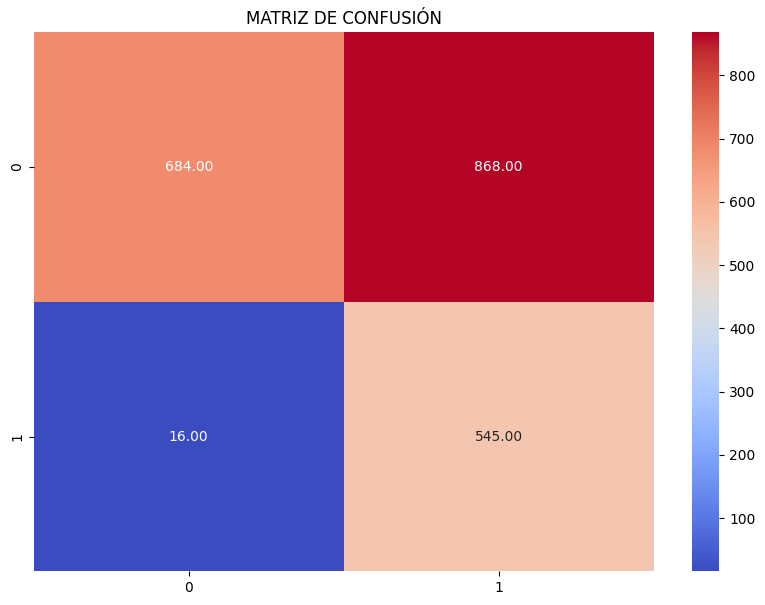

In [103]:
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(10, 7))

sns.heatmap(confusion_matrix(y_test, y_final), annot=True, cmap='coolwarm', fmt=".2f")

plt.title("MATRIZ DE CONFUSIÓN")
plt.show()

In [106]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import recall_score, precision_score, f1_score
from imblearn.pipeline import Pipeline as ImbPipeline  

pipeline_xgb_w = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    use_label_encoder=False
)

param_grid_w = {
    "n_estimators": [200, 300],
    "max_depth": [4, 5, 6],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_weight": [1, 3],
    "gamma": [0, 1],
    "scale_pos_weight": [2, 3, 4]  
}

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

grid_xgb_w ="recall",
    cv=cv,= GridSearchCV(
    estimator=pipeline_xgb_w,
    param_grid=param_grid_w,
    scorin
    n_jobs=-1,
    verbose=2
)

grid_xgb_w.fit(X_train, y_train)

best_xgb_w = grid_xgb_w.best_estimator_

y_scores_w = best_xgb_w.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.10, 0.90, 0.05)

for thr in thresholds:
    y_thr = (y_scores_w >= thr).astype(int)
    r = recall_score(y_test, y_thr)
    p = precision_score(y_test, y_thr)
    f = f1_score(y_test, y_thr)
    print(f"THR={thr:.2f} | Recall={r:.4f} | Precision={p:.4f} | F1={f:.4f}")

Fitting 4 folds for each of 576 candidates, totalling 2304 fits


c:\Users\koki2\Desktop\VENVS\ML_VENV\lib\site-packages\xgboost\training.py:199: UserWarning: [23:16:49] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


THR=0.10 | Recall=0.9822 | Precision=0.3597 | F1=0.5265
THR=0.15 | Recall=0.9733 | Precision=0.3853 | F1=0.5521
THR=0.20 | Recall=0.9537 | Precision=0.4044 | F1=0.5679
THR=0.25 | Recall=0.9394 | Precision=0.4233 | F1=0.5836
THR=0.30 | Recall=0.9091 | Precision=0.4363 | F1=0.5896
THR=0.35 | Recall=0.8948 | Precision=0.4518 | F1=0.6005
THR=0.40 | Recall=0.8734 | Precision=0.4689 | F1=0.6102
THR=0.45 | Recall=0.8556 | Precision=0.4863 | F1=0.6202
THR=0.50 | Recall=0.8307 | Precision=0.5011 | F1=0.6251
THR=0.55 | Recall=0.8075 | Precision=0.5148 | F1=0.6287
THR=0.60 | Recall=0.7825 | Precision=0.5406 | F1=0.6395
THR=0.65 | Recall=0.7469 | Precision=0.5639 | F1=0.6426
THR=0.70 | Recall=0.6845 | Precision=0.5836 | F1=0.6300
THR=0.75 | Recall=0.6275 | Precision=0.6111 | F1=0.6192
THR=0.80 | Recall=0.4991 | Precision=0.6437 | F1=0.5622
THR=0.85 | Recall=0.3939 | Precision=0.7175 | F1=0.5086


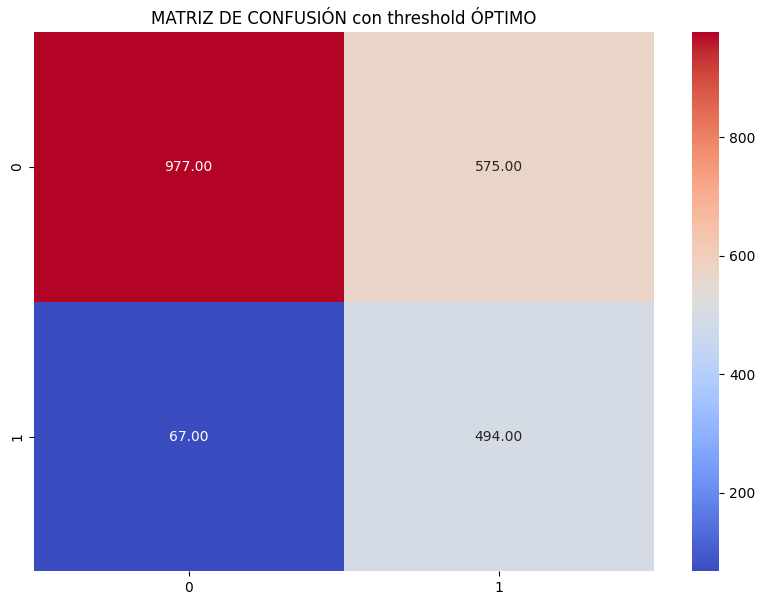

              precision    recall  f1-score   support

           0       0.94      0.63      0.75      1552
           1       0.46      0.88      0.61       561

    accuracy                           0.70      2113
   macro avg       0.70      0.76      0.68      2113
weighted avg       0.81      0.70      0.71      2113



In [109]:
from sklearn.metrics import confusion_matrix, classification_report

plt.figure(figsize=(10, 7))

y_scores = best_xgb.predict_proba(X_test)[:, 1]
thr = 0.30

y_final = (y_scores >= thr).astype(int)
sns.heatmap(confusion_matrix(y_test, y_final), annot=True, cmap='coolwarm', fmt=".2f")

plt.title("MATRIZ DE CONFUSIÓN con threshold ÓPTIMO")
plt.show()

print(classification_report(y_test, y_final))

## Vamos a entender qué tipo de clientes se van, por qué se van y tambien veremos si hay  grupos de clientes  con más riesgo

In [127]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import plotly.express as px

# ============================================
# 1. Seleccionar solo variables numéricas
# ============================================
X_num = X_train.select_dtypes(include=np.number)

# ============================================
# 2. Escalado
# ============================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)

# ============================================
# 3. K-Means (3 clusters) 
# ============================================
kmeans = KMeans(n_clusters=3, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

# ============================================
# 4. PCA con 3 componentes
# ============================================
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)


df_plot = pd.DataFrame({
    "PCA1": X_pca[:, 0],
    "PCA2": X_pca[:, 1],
    "PCA3": X_pca[:, 2],
    "Cluster": cluster_labels
})

fig = px.scatter_3d(
    df_plot,
    x="PCA1",
    y="PCA2",
    z="PCA3",
    color="Cluster",
    title="Clusters de Clientes (K-Means) – PCA 3 Componentes (3D)",
    opacity=0.75,
    symbol="Cluster",
    width=1200,    
    height=900    
)


fig.update_traces(marker=dict(size=2))
fig.show()


churn_dist = pd.crosstab(cluster_labels, y_train, normalize="index") * 100
churn_dist.columns = ["% No Churn", "% Churn"]
print(churn_dist)

       % No Churn    % Churn
row_0                       
0       85.804416  14.195584
1       93.129062   6.870938
2       55.511464  44.488536


El cluster 2 es el problemático, ya que en ese conjunto de empleados, casi la mitad (44%), abandonan la empresa. 

A continuación, vamos a obtener los valores promedio de todas las variables para los clientes del cluster 2

In [120]:
X_num = X_train.select_dtypes(include=np.number)

df_clusters = pd.DataFrame(X_num, copy=True)
df_clusters["cluster"] = cluster_labels

cluster_2 = df_clusters[df_clusters["cluster"] == 2].mean()
print(cluster_2)

Gender               0.513668
Senior Citizen       0.201058
Partner              0.315697
Dependents           0.137125
Tenure Months       -0.646207
Phone Service        0.843474
Multiple Lines       0.332451
Internet Service     0.541887
Online Security      0.224868
Online Backup        0.273369
Device Protection    0.250882
Tech Support         0.212522
Streaming TV         0.331570
Streaming Movies     0.324515
Contract             0.138448
Paperless Billing    0.681658
Payment Method       1.779982
Monthly Charges      0.121548
Total Charges       -0.509283
CLTV                -0.310567
cluster              2.000000
dtype: float64


## En el cluster 2 encontramos: 

-   Clientes jóvenes

-   De baja antigüedad (tenure bajo)

-   Sin contrato anual (casi todos month-to-month)

-   Con facturación mensual alta

-   Con pocos servicios adicionales (baja fidelización)

-   Bajo CLTV (poco valor futuro esperado)

-   Poco comprometidos con la empresa

-   Alto riesgo estructural de abandono

Como sabemos que el cluster 2 tiene una probabilidad de churn más alta, vamos a comprobar cómo funciona el mejor modelo  de XGBoost con este cluster problemático.



In [130]:
df_clusters = pd.DataFrame(X_num, copy=True)
df_clusters["cluster"] = cluster_labels

# Probabilidades de churn del modelo en TRAIN
y_scores_train = best_xgb.predict_proba(X_train)[:, 1]
df_clusters["pred_score"] = y_scores_train

# Score medio por cluster
cluster_pred_scores = df_clusters.groupby("cluster")["pred_score"].mean()

print("Score medio predicho por XGBoost en cada cluster:\n")
print(cluster_pred_scores)


Score medio predicho por XGBoost en cada cluster:

cluster
0    0.223447
1    0.142396
2    0.587864
Name: pred_score, dtype: float32


## Validación del modelo XGBoost sobre los clusters obtenidos

Con el fin de comprobar si el XGBoost es coherente con los patrones estructurales descubiertos mediante K-Means, se calculó la probabilidad media predicha de churn dentro de cada cluster.

En este análisis, se observa lo siguiente: 

Cluster 2 (el problemático): score medio = 0.5879
→ Cluster con mayor riesgo (44.5% de churn real). En este caso, XGBoost lo identifica correctamente como el grupo más propenso a abandonar.

Cluster 0 : score medio = 0.2234
→ Coherente con su churn real del 14%.

Cluster 1 : score medio = 0.1424
→ Coherente su churn real del 6.8%.

Este análisis confirma que XGBoost captura adecuadamente los patrones de comportamiento que explican el churn, reforzando la robustez y coherencia del modelo final seleccionado.